# Una CNN para estimar el oleaje desde imágenes SAR: ¿le gana al método físico?

**Resumen del cuaderno.** El objetivo es estimar la altura, el periodo y la dirección del oleaje a partir de imágenes SAR (radar de apertura sintética, *synthetic aperture radar*) de Sentinel-1, y comprobar con honestidad cuándo una CNN (red neuronal convolucional, *convolutional neural network*) mejora al método físico. Se comparan una CNN (PyTorch) sobre el espectro 2D de la imagen, XGBoost (*eXtreme Gradient Boosting*, árboles de decisión potenciados por gradiente) sobre rasgos escalares tipo CWAVE (conjunto de rasgos escalares del espectro de la imagen para estimar el oleaje con SAR) y la inversión física del cuaderno 03, primero con escenas simuladas con verdad conocida (con y sin saturación) y después con imágenes reales de un único sitio del Pacífico sur frente a Chile, con ERA5 (reanálisis atmosférico de quinta generación del Centro Europeo de Predicciones Meteorológicas a Plazo Medio, ECMWF) como referencia. Resultados principales: en simulación la inversión física es la mejor en altura si la física es lineal, y cuando aparece la saturación CNN y XGBoost bajan el sesgo de unos -41 % a unos -3 %, pero ninguno de los modelos aprendidos acierta fuera de lo visto; con el mar real de un sitio (187 imágenes de 2016 contra ERA5, validación cruzada por día), el método físico subestima la altura un 13 %, no da un periodo útil y devuelve siempre el eje de alcance como dirección; XGBoost y la CNN, entrenados con ERA5, bajan el error de altura de 0,99 m (predecir la media) a 0,67 y 0,61 m y el de periodo de 1,17 s a 0,55 y 0,66 s, con un empate técnico entre los dos y un control que descarta que sea climatología. Con solo 8 imágenes (el piloto de enero) la CNN no aprendía nada, así que el cuello de botella son las etiquetas y el número de imágenes independientes, no la arquitectura.

**Objetivo de la sesión.** En el cuaderno 03 (sección 12) sacamos de una viñeta de Sentinel-1 la longitud de onda, el periodo, la dirección y la altura del oleaje con un método **físico** (invertir la función de transferencia $|T|^2$). Aquí probamos la alternativa de **aprendizaje automático**: una red convolucional (CNN, PyTorch) que recibe el espectro 2D de la imagen y devuelve $H_{m0}$ (altura significativa espectral), $T_p$ (periodo de pico) y la dirección. Y la comparamos, con un rival de verdad, contra el método físico y contra XGBoost sobre rasgos escalares tipo CWAVE.

| Parte | Qué se hace |
|---|---|
| 1 a 2 | Simulador de escenas SAR con **verdad conocida**, con y sin saturación, y la representación de entrada |
| 3 a 4 | CNN, XGBoost y método físico en tres test: dentro del rango, **saturado** y **más alto** que lo visto |
| 5 | Las 8 viñetas reales: ¿coinciden los métodos? (no hay verdad real, solo consistencia) |
| 6 | Mar real de un sitio con ERA5: piloto de enero (8 imágenes) y después 187 imágenes de 2016 con validación cruzada por día, CNN, XGBoost, qué ha aprendido la red y la serie temporal del año |

**Aviso desde el principio.** Todo el entrenamiento usa **simulaciones generadas con nuestro propio modelo**. Un buen resultado en simulación demuestra que la red aprende lo que le enseñamos, no que acierte con el mar real. Lo que sí mide este cuaderno es **dónde** se rompe cada método. La prueba de verdad es la sección 6.

**Datos.** Las 8 viñetas reales de las secciones 5 y 6.1 a 6.4 son un extracto de **TenGeoP-SARwv** ([Wang et al., 2019](https://doi.org/10.1002/gdj3.73), [doi:10.17882/56796](https://doi.org/10.17882/56796), clase F "Pure Ocean Waves"), derivadas de *Contains modified Copernicus Sentinel data (2016)*, ESA (Agencia Espacial Europea). Las 187 imágenes de 2016 de la sección 6.5 son de la misma colección (clase F); del repositorio solo se guardan sus espectros ya calculados, no las imágenes. Licencia **CC BY-NC-SA 4.0 (Creative Commons Atribución, No Comercial, Compartir Igual)**: uso no comercial y compartir igual, con atribución.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/wind_cases/05_cnn_oleaje_sar.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta y descarga la carpeta `datos/` del repositorio. Los tiempos de este cuaderno se midieron en un equipo con varios núcleos; un entorno de CPU gratuito de Colab (unos 2 núcleos) puede tardar varias veces más.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan y, en Colab,
# descarga la carpeta datos/ (unos 22 MB) del repositorio del curso si no está junto al cuaderno.
import importlib.util, os, shutil, subprocess, sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'xgboost': 'xgboost',
}  # nombre de importación -> requisito de pip
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

REPO = 'https://github.com/fborbon/academy.git'         # repositorio del curso (carpeta neural-networks-1002/wind_cases)
if not Path('datos').exists():
    print('Descargando datos/ del repositorio del curso ...')
    tmp = Path('_repo_curso')
    shutil.rmtree(tmp, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', REPO, str(tmp)], check=True)
    subprocess.run(['git', '-C', str(tmp), 'sparse-checkout', 'set', 'neural-networks-1002/wind_cases/datos'], check=True)
    shutil.copytree(tmp / 'neural-networks-1002' / 'wind_cases' / 'datos', 'datos')
    shutil.rmtree(tmp, ignore_errors=True)
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()} | datos/: {len(list(Path('datos').glob('*')))} archivos")

Entorno: Python 3.12.3 | local | CPUs: 8 | datos/: 20 archivos


<!-- toc -->
**Contenido**

* [1. Entorno y semillas](#1.-Entorno-y-semillas)
* [2. Simulador de escenas SAR con verdad conocida y dos regímenes](#2.-Simulador-de-escenas-SAR-con-verdad-conocida-y-dos-regímenes)
  * [Conjuntos de datos](#Conjuntos-de-datos)
* [3. Modelos y entrenamiento](#3.-Modelos-y-entrenamiento)
* [4. Resultados en los tres test](#4.-Resultados-en-los-tres-test)
* [5. Aplicación a las 8 viñetas reales](#5.-Aplicación-a-las-8-viñetas-reales)
* [6. Mar real en un solo sitio, con ERA5 como referencia](#6.-Mar-real-en-un-solo-sitio,-con-ERA5-como-referencia)
  * [6.1 Cómo se ven las imágenes](#6.1-Cómo-se-ven-las-imágenes)
  * [6.2 Leer el análisis sobre las imágenes](#6.2-Leer-el-análisis-sobre-las-imágenes)
  * [6.3 Método físico frente a ERA5 (enero, 8 imágenes)](#6.3-Método-físico-frente-a-ERA5-%28enero,-8-imágenes%29)
  * [6.4 Piloto de la CNN con las 8 imágenes](#6.4-Piloto-de-la-CNN-con-las-8-imágenes)
  * [6.5 El año completo: 187 imágenes y 10 meses de ERA5](#6.5-El-año-completo:-187-imágenes-y-10-meses-de-ERA5)
  * [6.6 El método físico frente a ERA5, con 187 imágenes](#6.6-El-método-físico-frente-a-ERA5,-con-187-imágenes)
  * [6.7 Modelos entrenados con ERA5 frente a la media y el método físico calibrado](#6.7-Modelos-entrenados-con-ERA5-frente-a-la-media-y-el-método-físico-calibrado)
  * [6.8 Qué ha aprendido la CNN](#6.8-Qué-ha-aprendido-la-CNN)
  * [6.9 Serie temporal del año: ERA5 frente a las estimaciones SAR](#6.9-Serie-temporal-del-año:-ERA5-frente-a-las-estimaciones-SAR)
  * [6.10 Límites de lo medido y qué falta](#6.10-Límites-de-lo-medido-y-qué-falta)
  * [6.11 Apéndice: cómo repetir la descarga (CDS y SEANOE)](#6.11-Apéndice:-cómo-repetir-la-descarga-%28CDS-y-SEANOE%29)
* [7. Conclusión: cuándo usar una CNN para oleaje desde SAR](#7.-Conclusión:-cuándo-usar-una-CNN-para-oleaje-desde-SAR)
* [8. Ejercicios](#8.-Ejercicios)

*Para saltar a una sección usa el índice del panel lateral izquierdo: en JupyterLab la pestaña "Table of Contents" y en VS Code la vista "Outline" (se generan solas a partir de los títulos). Los enlaces de esta lista llevan bien a las secciones cercanas, pero JupyterLab no siempre llega a las lejanas porque no dibuja todas las celdas a la vez.*


## 1. Entorno y semillas

Semillas fijas, CPU (unidad central de procesamiento) y generación de escenas en paralelo (8 procesos). Todo el cuaderno tarda unos minutos; el tiempo total se imprime al final.

In [1]:
import os
import time, json
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xgboost as xgb
import matplotlib.pyplot as plt
from scipy import ndimage

SEMILLA = 0
np.random.seed(SEMILLA); torch.manual_seed(SEMILLA); torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
G = 9.81
DATOS = Path("datos")
T0 = time.time()
print("torch", torch.__version__, "| xgboost", xgb.__version__)

torch 2.15.0+cpu | xgboost 3.4.1



## 2. Simulador de escenas SAR con verdad conocida y dos regímenes

Reutilizamos el simulador del cuaderno 03 (suma de 400 ondas con espectro JONSWAP (*Joint North Sea Wave Project*, espectro empírico de mar de viento) y dispersión direccional $\cos^{2s}$, pasadas por la función de transferencia $T$ y con *speckle* multiplicativo) y lo hacemos aleatorio: $H_{m0}$ de 1 a 8 m, $T_p$ de 9 a 20 s, dirección de procedencia de 0° a 360°, $s$ (dispersión direccional) de 15 a 80, ruido de *speckle* de 0,05 a 0,12, las dos subfranjas WV1 (subfranja de incidencia ≈ 23,5°) y WV2 (subfranja de incidencia ≈ 36,5°) y tamaños de píxel de 36 a 41 m (alcance) y 39,5 a 43 m (acimut). El objetivo de $H_{m0}$ es la altura **visible** (solo olas de más de 100 m).

Dos regímenes:

* **Lineal** (`"lin"`): el modelo cuasi-lineal del cuaderno 03, el mismo que supone el método físico. Para olas que viajan en acimut da modulaciones mayores que las reales.
* **Con saturación** (`"sat"`): añade, **de forma aproximada y cualitativa**, dos efectos que el modelo lineal no tiene: (1) un **corte en acimut** (suavizado gaussiano a lo largo de las filas de anchura $(R/V)\,u_{rms}$, con $u_{rms}=\omega_p H_{m0}/4$ la velocidad orbital rms) y (2) una **compresión** de la modulación, $I=1+0{,}6\tanh[(I-1)/0{,}6]$. No es la teoría completa de [Hasselmann y Hasselmann (1991)](https://doi.org/10.1029/91JC00302) ni un modelo validado: sirve para ver cómo reaccionan los métodos cuando la física real se sale de la lineal, como ocurre en las viñetas reales (modulación rms de 0,16 a 0,30 frente a 0,8 de la simulación lineal).

**Representaciones de entrada.**

* **CNN:** el espectro 2D de la imagen (Welch con ventanas de 128 píxeles, 50 % de solape, 12 ventanas por escena) en $\log_{10}$, recortado a ±48 celdas y promediado 2 × 2, es decir una imagen de 48 × 48, más un canal que indica la subfranja. Se calcula en los **ejes de la imagen**, así no hace falta conocer la órbita.
* **XGBoost:** 30 rasgos escalares tipo CWAVE: energía en 7 bandas radiales y 12 sectores angulares (módulo 180°), varianza total, posición y orientación del pico, contraste, momentos radiales y angulares.
* **Método físico:** el del cuaderno 03 (restar el suelo de *speckle*, dividir por $|T|^2$, integrar), con la misma ventana de 128 píxeles.

**Objetivos.** $\ln H_{m0}$, $T_p$ y la dirección como $(\cos 2\psi,\sin 2\psi)$: duplicar el ángulo hace que $\psi$ (dirección de procedencia) y $\psi+180^\circ$ den lo mismo, que es justo la ambigüedad de una imagen de intensidad. El error angular se calcula igual, con ángulos dobles.

In [2]:
# --- Funciones del cuaderno 03 (sección 12), copiadas para que este cuaderno sea autónomo ---
THETA_INC = {"wv1": 23.5, "wv2": 36.5}                     # incidencia media de cada subfranja [°]
R_V = {"wv1": 756e3 / 7.5e3, "wv2": 862e3 / 7.5e3}         # distancia oblicua / velocidad del satélite [s]

def convergencia(lon, lat):
    zona = int((lon + 180) // 6) + 1
    return np.rad2deg(np.arctan(np.tan(np.deg2rad(lon - (-183 + 6 * zona))) * np.sin(np.deg2rad(lat))))

def welch2d(I, ven=192, paso=96):
    w = np.outer(np.hanning(ven), np.hanning(ven)); acc, n = 0, 0
    for i in range(0, I.shape[0] - ven + 1, paso):
        for j in range(0, I.shape[1] - ven + 1, paso):
            x = (I[i:i + ven, j:j + ven] - I[i:i + ven, j:j + ven].mean()) * w
            acc = acc + np.abs(np.fft.fft2(x)) ** 2; n += 1
    return np.fft.fftshift(acc / n / (ven ** 2 * (w ** 2).sum()))

def mtf(kr, ka, sub):
    th_i = np.deg2rad(THETA_INC[sub]); k = np.maximum(np.hypot(kr, ka), 1e-9); w = np.sqrt(G * k)
    T_incl = 4j * kr / np.tan(th_i) / (1 + np.sin(th_i) ** 2)
    T_vb = -R_V[sub] * ka * w * (np.sin(th_i) * kr / k + 1j * np.cos(th_i))
    return T_incl + T_vb

VEN = 128                                                     # ventana de Welch de este cuaderno (píxeles)

def espectro_sar(a, ec, er, sub, lon, lat, lam_lim=(100, 800), ven=VEN):
    dc, dr = np.linalg.norm(ec), np.linalg.norm(er)
    I = a / ndimage.gaussian_filter(a, 15, mode="nearest") - 1
    P = welch2d(I, ven, ven // 2)
    kc = np.fft.fftshift(np.fft.fftfreq(ven, dc)) * 2 * np.pi
    kr = np.fft.fftshift(np.fft.fftfreq(ven, dr)) * 2 * np.pi
    KC, KR = np.meshgrid(kc, kr); K = np.hypot(KC, KR)
    dens = P / ((kc[1] - kc[0]) * (kr[1] - kr[0]))
    ruido = np.median(dens[K > 0.75 * np.pi / max(dc, dr)])
    dens_s = np.clip(dens - ruido, 0, None)
    T2 = np.abs(mtf(KC, KR, sub)) ** 2
    lam = 2 * np.pi / np.maximum(K, 1e-9)
    F = np.where((T2 > 1e-4) & (lam > lam_lim[0]) & (lam < lam_lim[1]), dens_s / np.maximum(T2, 1e-4), 0)
    return dict(kc=kc, kr=kr, KC=KC, KR=KR, K=K, dens=dens, dens_s=dens_s, F=F, ruido=ruido, ec=ec, er=er, dc=dc, dr=dr,
                gam=convergencia(lon, lat), sub=sub, mod_rms=I.std(), lam_lim=lam_lim)

f_sar = np.linspace(0.04, 0.25, 85)
th = np.deg2rad(np.arange(0, 360, 2.0))

def vector_geo(kc, kr, R):
    ec_u, er_u = R["ec"] / R["dc"], R["er"] / R["dr"]
    return kc * ec_u[0] + kr * er_u[0], kc * ec_u[1] + kr * er_u[1]

def a_E_fth(R, f_, theta):
    k = (2 * np.pi * f_) ** 2 / G
    az = theta[None, :] + np.pi - np.deg2rad(R["gam"])
    kE, kN = k[:, None] * np.sin(az), k[:, None] * np.cos(az)
    ec_u, er_u = R["ec"] / R["dc"], R["er"] / R["dr"]
    kc, kr = kE * ec_u[0] + kN * ec_u[1], kE * er_u[0] + kN * er_u[1]
    ic, ir = (kc - R["kc"][0]) / (R["kc"][1] - R["kc"][0]), (kr - R["kr"][0]) / (R["kr"][1] - R["kr"][0])
    Fk = ndimage.map_coordinates(R["F"], [ir, ic], order=1, mode="constant", cval=0)
    return Fk * (k * 8 * np.pi ** 2 * f_ / G)[:, None]

def hm0_de_E(f_, theta, E):
    S = np.clip(E, 0, None).sum(1) * (theta[1] - theta[0])
    return 4 * np.sqrt((S * np.gradient(f_)).sum())

def metodo_fisico(R):
    # Hm0 (integral de F), Tp (de la longitud de onda del pico) y las dos direcciones del pico
    E = a_E_fth(R, f_sar, th)
    Fs = ndimage.gaussian_filter(R["F"], 1)
    i = np.unravel_index(Fs.argmax(), Fs.shape)
    lam = 2 * np.pi / R["K"][i]
    kE, kN = vector_geo(R["KC"][i], R["KR"][i], R)
    desde = (np.rad2deg(np.arctan2(kE, kN)) + R["gam"] + 180) % 360
    return dict(Hm0=hm0_de_E(f_sar, th, E), Tp=np.sqrt(2 * np.pi * lam / G), desde=desde)

def dif_ang(a, b):
    return (a - b + 180) % 360 - 180

def error_dir(d1, d2):
    # Error angular [°] con ambigüedad de 180°: se compara el ángulo doble
    return np.abs(dif_ang(2 * np.asarray(d1), 2 * np.asarray(d2))) / 2

# --- Viñetas reales (8 de TenGeoP-SARwv, clase F) ---
zsar = np.load(DATOS / "sar_s1_wv_extracto.npz")
meta_sar = json.loads(str(zsar["meta"]))
IMG = [dict(a=zsar[f"img{k}"].astype(float) * 4.5777065690089265e-05, ec=zsar[f"ec{k}"], er=zsar[f"er{k}"], **m)
       for k, m in enumerate(meta_sar)]
print(len(IMG), "viñetas reales cargadas; píxel medio", round(np.mean([np.linalg.norm(i["ec"]) for i in IMG]), 1),
      "x", round(np.mean([np.linalg.norm(i["er"]) for i in IMG]), 1), "m")

8 viñetas reales cargadas; píxel medio 39.9 x 41.4 m


In [3]:
import os
def simula_sar(Hs, Tp, dir_desde, s, sub, dc, dr, forma=(256, 320), n_comp=400, sigma_ruido=0.087,
               semilla=0, lam_corte=100, saturacion=False):
    # Escena SAR de un swell con verdad conocida. Los ejes de la imagen son: columnas = este, filas = norte (mallas ec=(dc,0), er=(0,dr)).
    # saturacion=True añade, de forma APROXIMADA y cualitativa, los dos efectos no lineales que el modelo cuasi-lineal no tiene:
    #   (1) corte en acimut: suavizado gaussiano a lo largo de las filas, de anchura (R/V)·u_rms (u_rms = velocidad orbital rms)
    #   (2) compresión de la modulación: I = 1 + 0.6·tanh((I-1)/0.6)
    # No es la teoría completa de Hasselmann y Hasselmann (1991): sirve para ver cómo reaccionan los métodos fuera de su régimen.
    r = np.random.default_rng(semilla)
    fp = 1 / Tp; fg = np.linspace(0.5 * fp, 3 * fp, 2000)
    sg = np.where(fg <= fp, 0.07, 0.09)
    S = fg ** -5 * np.exp(-1.25 * (fp / fg) ** 4) * 3.3 ** np.exp(-(fg - fp) ** 2 / (2 * sg ** 2 * fp ** 2))
    cdf = np.cumsum(S); cdf /= cdf[-1]
    fj = np.interp(r.uniform(size=n_comp), cdf, fg)
    Aj = np.sqrt(2 * (Hs / 4) ** 2 / n_comp)
    phi_to = np.deg2rad(dir_desde) + r.normal(0, np.sqrt(1 / s), n_comp) + np.pi
    kj = (2 * np.pi * fj) ** 2 / G
    ok = np.nonzero(2 * np.pi / kj > lam_corte)[0]
    k_al, k_ac = kj * np.sin(phi_to), kj * np.cos(phi_to)         # alcance = columnas (este), acimut = filas (norte)
    T = mtf(k_al, k_ac, sub); fase = r.uniform(0, 2 * np.pi, n_comp)
    Ar = np.exp(1j * np.outer(np.arange(forma[0]) * dr, k_ac[ok])) * (Aj * np.abs(T[ok]) * np.exp(1j * (fase[ok] + np.angle(T[ok]))))
    Ac = np.exp(1j * np.outer(np.arange(forma[1]) * dc, k_al[ok]))
    m = (Ar @ Ac.T).real
    if saturacion:
        sig_m = R_V[sub] * (2 * np.pi * fp) * Hs / 4                # desplazamiento rms en acimut [m]
        m = ndimage.gaussian_filter1d(m, sig_m / dr, axis=0, mode="wrap")
        m = 0.6 * np.tanh(m / 0.6)
    I = (1 + m) * (1 + sigma_ruido * r.standard_normal(forma))
    return I, Hs * np.sqrt(len(ok) / n_comp)

# --- Representaciones de entrada ---
MEDIO = 48                                                     # semiancho del recorte del espectro [celdas de Welch]
def entrada_cnn(R):
    # Espectro de la imagen (sin restar nada) en log10, recorte central de ±48 celdas y promedio 2x2 -> 48x48
    c = VEN // 2
    z = np.log10(R["dens"][c - MEDIO:c + MEDIO, c - MEDIO:c + MEDIO] + 1e-3)
    return z.reshape(MEDIO, 2, MEDIO, 2).mean((1, 3)).astype(np.float32)

KB = 2 * np.pi / np.array([800, 560, 400, 290, 210, 160, 125, 100.0])      # bordes radiales (de 800 m a 100 m)
def rasgos_cwave(R):
    # Rasgos escalares tipo CWAVE: perfiles radial y angular de energía, pico, contraste, momentos
    d = R["dens_s"]; K = R["K"]; psi = np.mod(np.arctan2(R["KC"], R["KR"]), np.pi)       # ángulo de k respecto al eje de filas, módulo 180°
    banda = (K >= KB[0]) & (K < KB[-1])
    E = np.where(banda, d, 0); tot = E.sum() + 1e-12
    rad = np.array([E[(K >= a) & (K < b)].sum() for a, b in zip(KB[:-1], KB[1:])]) / tot
    ang = np.array([E[(psi >= a) & (psi < a + np.pi / 12)].sum() for a in np.arange(0, np.pi, np.pi / 12)]) / tot
    Fs = ndimage.gaussian_filter(np.where(banda, d, 0), 1.5)
    i = np.unravel_index(Fs.argmax(), Fs.shape)
    kp, pp = K[i], np.arctan2(R["KC"][i], R["KR"][i])
    kmed = (E * K).sum() / tot; kstd = np.sqrt((E * (K - kmed) ** 2).sum() / tot)
    c2, s2 = (E * np.cos(2 * psi)).sum() / tot, (E * np.sin(2 * psi)).sum() / tot
    contraste = Fs.max() / (np.median(d[banda]) + 1e-9)
    return np.r_[rad, ang, np.log10(tot * (R["kc"][1] - R["kc"][0]) * (R["kr"][1] - R["kr"][0]) + 1e-9), kp, np.cos(2 * pp), np.sin(2 * pp),
                 np.log10(contraste), kmed, kstd, c2, s2, np.hypot(c2, s2), float(R["sub"] == "wv2")]

def una_escena(args):
    # Genera una escena, la procesa y devuelve entrada de la CNN, rasgos, verdad y estimación del método físico
    semilla, modo, rg = args
    try:
        from threadpoolctl import threadpool_limits
        threadpool_limits(1)
    except Exception:
        pass
    r = np.random.default_rng(10_000 + semilla)
    Hs, Tp = r.uniform(*rg["Hs"]), r.uniform(*rg["Tp"])
    dd, s = r.uniform(0, 360), np.exp(r.uniform(np.log(15), np.log(80)))
    sub = "wv1" if r.uniform() < 0.5 else "wv2"
    dc, dr = r.uniform(36, 41), r.uniform(39.5, 43)
    sig = r.uniform(0.05, 0.12)
    I, Hs_vis = simula_sar(Hs, Tp, dd, s, sub, dc, dr, sigma_ruido=sig, semilla=semilla, saturacion=(modo == "sat"))
    R = espectro_sar(I, np.array([dc, 0.0]), np.array([0.0, dr]), sub, 3.0, 0.0)    # lon=3°, lat=0: convergencia nula
    fis = metodo_fisico(R)
    return dict(x=entrada_cnn(R), sub=float(sub == "wv2"), rasgos=rasgos_cwave(R),
                y=np.array([Hs_vis, Tp, dd]), fis=np.array([fis["Hm0"], fis["Tp"], fis["desde"]]), mod_rms=I.std())

def genera(n, semilla0, modo, rg, nombre):
    t = time.time()
    with ProcessPoolExecutor(min(8, os.cpu_count() or 1), mp_context=mp.get_context("fork")) as ex:
        res = list(ex.map(una_escena, [(semilla0 + i, modo, rg) for i in range(n)], chunksize=16))
    out = dict(x=np.stack([r["x"] for r in res]), sub=np.array([r["sub"] for r in res], np.float32),
               rasgos=np.stack([r["rasgos"] for r in res]), y=np.stack([r["y"] for r in res]),
               fis=np.stack([r["fis"] for r in res]), mod_rms=np.array([r["mod_rms"] for r in res]))
    print(f"{nombre:34s} {n:5d} escenas en {time.time() - t:4.0f} s")
    return out


### Conjuntos de datos

2 000 escenas lineales y 1 000 con saturación para entrenar, 300 + 300 para validar (parada temprana) y tres **test** que nunca se ven al entrenar:

* **A:** lineal y dentro del rango de entrenamiento. Es el terreno del método físico (el simulador y la inversión comparten modelo).
* **B:** con **saturación** y dentro del rango. Aquí el modelo lineal ya no es la verdad.
* **C:** lineal pero con $H_{m0}$ de **9 a 12 m**, fuera del rango visto (1 a 8 m).

Hay dos variantes de cada modelo de aprendizaje: **lineal** (solo escenas lineales) y **mezcla** (lineales más saturadas). La variante mezcla muestra qué puede aprender un modelo si el simulador contiene el efecto, algo que el método físico no puede hacer.

In [4]:
import copy
RG_IN, RG_GRANDE = dict(Hs=(1, 8), Tp=(9, 20)), dict(Hs=(9, 12), Tp=(9, 20))
def une(a, b): return {k: np.concatenate([a[k], b[k]]) for k in a}

# Entrenamiento: 2000 escenas lineales (+ 1000 con saturación para las variantes "mezcla"); validación y tres test
d_lin = genera(2000, 0, "lin", RG_IN, "entrenamiento lineal")
d_sat = genera(1000, 20_000, "sat", RG_IN, "entrenamiento con saturación")
v_lin = genera(300, 40_000, "lin", RG_IN, "validación lineal")
v_sat = genera(300, 50_000, "sat", RG_IN, "validación con saturación")
t_lin = genera(400, 60_000, "lin", RG_IN, "TEST A: lineal, mismo rango")
t_sat = genera(400, 70_000, "sat", RG_IN, "TEST B: saturado, mismo rango")
t_gra = genera(300, 80_000, "lin", RG_GRANDE, "TEST C: lineal, Hm0 de 9 a 12 m")
d_mez, v_mez = une(d_lin, d_sat), une(v_lin, v_sat)
print(f"modulación rms mediana: lineal {np.median(d_lin['mod_rms']):.2f} | saturado {np.median(d_sat['mod_rms']):.2f} | "
      f"{len(IMG)} viñetas reales {np.median([espectro_sar(i['a'], i['ec'], i['er'], i['sub'], i['lon'], i['lat'])['mod_rms'] for i in IMG]):.2f}")

entrenamiento lineal                2000 escenas en    8 s


entrenamiento con saturación        1000 escenas en    4 s


validación lineal                    300 escenas en    2 s


validación con saturación            300 escenas en    2 s


TEST A: lineal, mismo rango          400 escenas en    2 s


TEST B: saturado, mismo rango        400 escenas en    2 s


TEST C: lineal, Hm0 de 9 a 12 m      300 escenas en    1 s


modulación rms mediana: lineal 0.98 | saturado 0.32 | 8 viñetas reales 0.25


**Lectura.** La modulación rms mediana de la simulación **lineal** es de 0,98, más del triple que la de las 8 viñetas reales (0,25), mientras que la **saturada** (0,32) se parece mucho más. Esto no demuestra que la saturación simulada sea correcta, pero sí que el régimen lineal no es el que se ve en el mar real, y que el método físico se apoya en él.


## 3. Modelos y entrenamiento

* **CNN:** tres capas de convolución (8, 16 y 32 filtros de 3 × 3, con *max pooling*) y dos capas densas, unos 28 000 parámetros, pérdida MSE (error cuadrático medio) sobre los 4 objetivos estandarizados, Adam, parada temprana con la validación (paciencia 5, máximo 30 épocas) y **3 semillas**.
* **XGBoost:** un modelo por objetivo (4), 600 árboles como máximo, parada temprana con la misma validación.
* **Físico:** sin entrenamiento.

In [5]:
# --- Objetivos: log Hm0 y Tp (estandarizados), y la dirección como (cos 2ψ, sin 2ψ) por la ambigüedad de 180° ---
def objetivos(y):
    psi2 = np.deg2rad(2 * y[:, 2])
    return np.c_[np.log(y[:, 0]), y[:, 1], np.cos(psi2), np.sin(psi2)].astype(np.float32)

def decodifica(o):
    # (log Hm0, Tp, cos, sin) -> (Hm0, Tp, dirección en [0, 180) )
    return np.c_[np.exp(o[:, 0]), o[:, 1], (np.rad2deg(np.arctan2(o[:, 3], o[:, 2])) / 2) % 180]

class ConjuntoCNN:
    # Normaliza la entrada y el objetivo con estadísticos del conjunto de entrenamiento
    def __init__(self, d):
        self.mu_x, self.sd_x = d["x"].mean(), d["x"].std()
        o = objetivos(d["y"]); self.mu_y, self.sd_y = o[:, :2].mean(0), o[:, :2].std(0)
    def tensores(self, d):
        x = torch.from_numpy(((d["x"] - self.mu_x) / self.sd_x)[:, None])
        x = torch.cat([x, torch.from_numpy(d["sub"])[:, None, None, None].expand(-1, 1, MEDIO, MEDIO)], 1)
        o = objetivos(d["y"]); o[:, :2] = (o[:, :2] - self.mu_y) / self.sd_y
        return x.float(), torch.from_numpy(o)
    def inversa(self, p):
        p = p.copy(); p[:, :2] = p[:, :2] * self.sd_y + self.mu_y
        return decodifica(p)

class CNNOleaje(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(2, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 48 -> 24
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 24 -> 12
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))    # 12 -> 6
        self.cabeza = nn.Sequential(nn.Flatten(), nn.Linear(32 * 6 * 6, 96), nn.ReLU(), nn.Dropout(0.1), nn.Linear(96, 4))
    def forward(self, x):
        return self.cabeza(self.conv(x))

def entrena_cnn(d_tr, d_va, semilla, epocas=30, paciencia=5, lote=64, lr=2e-3):
    torch.manual_seed(semilla); np.random.seed(semilla)
    cj = ConjuntoCNN(d_tr); Xtr, Ytr = cj.tensores(d_tr); Xva, Yva = cj.tensores(d_va)
    m = CNNOleaje(); opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=1e-5)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    mejor, mejores_pesos, sin_mejora, hist = 1e9, None, 0, []
    for ep in range(epocas):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), lote):
            b = perm[i:i + lote]; opt.zero_grad()
            nn.functional.mse_loss(m(Xtr[b]), Ytr[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad(): lv = nn.functional.mse_loss(m(Xva), Yva).item()
        sch.step(lv); hist.append(lv)
        if lv < mejor - 1e-5: mejor, mejores_pesos, sin_mejora = lv, copy.deepcopy(m.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    m.load_state_dict(mejores_pesos); m.eval()
    return m, cj, hist

def predice_cnn(m, cj, d):
    X, _ = cj.tensores(d)
    with torch.no_grad(): return cj.inversa(m(X).numpy())

def entrena_xgb(d_tr, d_va, semilla=0):
    o_tr, o_va = objetivos(d_tr["y"]), objetivos(d_va["y"]); mods = []
    for j in range(4):
        mod = xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                               early_stopping_rounds=30, tree_method="hist", n_jobs=4, random_state=semilla)
        mod.fit(d_tr["rasgos"], o_tr[:, j], eval_set=[(d_va["rasgos"], o_va[:, j])], verbose=False); mods.append(mod)
    return mods

def predice_xgb(mods, d):
    return decodifica(np.c_[[m.predict(d["rasgos"]) for m in mods]].T)

def metricas(pred, y):
    # pred, y: columnas (Hm0, Tp, dirección). Devuelve sesgo y RMSE de Hm0, RMSE de Tp y error angular medio
    e = pred[:, 0] - y[:, 0]
    return {"Hm0 sesgo [%]": 100 * np.median(pred[:, 0] / y[:, 0] - 1), "Hm0 RMSE [m]": np.sqrt((e ** 2).mean()),
            "Hm0 error medio [%]": 100 * np.mean(np.abs(pred[:, 0] / y[:, 0] - 1)),
            "Tp RMSE [s]": np.sqrt(((pred[:, 1] - y[:, 1]) ** 2).mean()),
            "dir error medio [°]": error_dir(pred[:, 2], y[:, 2]).mean()}

In [6]:
t_ent = time.time()
SEMILLAS = [0, 1, 2]
xgb_lin, xgb_mez = entrena_xgb(d_lin, v_lin), entrena_xgb(d_mez, v_mez)
print(f"XGBoost (2 variantes, 4 modelos cada una): {time.time() - t_ent:.0f} s")
cnn_lin, cnn_mez = [], []
for nombre, d_tr, d_va, lista in [("lineal", d_lin, v_lin, cnn_lin), ("mezcla", d_mez, v_mez, cnn_mez)]:
    for s in SEMILLAS:
        t0 = time.time(); m, cj, h = entrena_cnn(d_tr, d_va, s)
        lista.append((m, cj)); print(f"CNN {nombre}, semilla {s}: {len(h)} épocas, {time.time() - t0:.0f} s, pérdida de validación {min(h):.4f}")
print(f"entrenamiento total: {time.time() - t_ent:.0f} s")

XGBoost (2 variantes, 4 modelos cada una): 4 s


CNN lineal, semilla 0: 30 épocas, 12 s, pérdida de validación 0.0143


CNN lineal, semilla 1: 30 épocas, 12 s, pérdida de validación 0.0138


CNN lineal, semilla 2: 30 épocas, 12 s, pérdida de validación 0.0150


CNN mezcla, semilla 0: 30 épocas, 18 s, pérdida de validación 0.0193


CNN mezcla, semilla 1: 30 épocas, 18 s, pérdida de validación 0.0202


CNN mezcla, semilla 2: 30 épocas, 18 s, pérdida de validación 0.0201
entrenamiento total: 94 s


**Lectura del coste.** Cada CNN tarda unos 30 s con 2 000 escenas y unos 55 s con 3 000 (CPU, 4 hilos); los 8 modelos de XGBoost, 7 s en total. Generar las escenas (unos 90 s con 8 procesos) cuesta más que entrenar. El método físico no se entrena.


## 4. Resultados en los tres test

Métricas: sesgo mediano de $H_{m0}$ (%), RMSE (raíz del error cuadrático medio) de $H_{m0}$ (m), error medio relativo de $H_{m0}$ (%), RMSE de $T_p$ (s) y error angular medio (°, con la ambigüedad de 180°). La última columna es la desviación entre las 3 semillas de la CNN (solo se ve en la CNN, el resto no tiene aleatoriedad en el entrenamiento).

Hm0 sesgo [%]  Hm0 RMSE [m]  \
A lineal físico (inversión por |T|²)             1.31          0.33   
         XGBoost, entrenado lineal               1.36          0.39   
         XGBoost, entrenado con mezcla           1.27          0.41   
         CNN, entrenada lineal                   1.09          0.33   
         CNN, entrenada con mezcla               1.09          0.41   

                                        Hm0 error medio [%]  Tp RMSE [s]  \
A lineal físico (inversión por |T|²)                   3.06         1.13   
         XGBoost, entrenado lineal                     7.47         0.23   
         XGBoost, entrenado con mezcla                 8.49         0.25   
         CNN, entrenada lineal                         6.27         0.50   
         CNN, entrenada con mezcla                     8.55         0.47   

                                        dir error medio [°]  \
A lineal físico (inversión por |T|²)                   3.65   
         XGBoost, entrenado lineal                     1.01   
         XGBoost, entrenado con mezcla                 1.08   
         CNN, entrenada lineal                         1.33   
         CNN, entrenada con mezcla                     1.40   

                                        desv. semillas, Hm0 error [%]  
A lineal físico (inversión por |T|²)                              NaN  
         XGBoost, entrenado lineal                                NaN  
         XGBoost, entrenado con mezcla                            NaN  
         CNN, entrenada lineal                                   0.20  
         CNN, entrenada con mezcla                               0.39

Hm0 sesgo [%]  Hm0 RMSE [m]  \
B saturado físico (inversión por |T|²)           -41.40          2.67   
           XGBoost, entrenado lineal             -49.40          2.84   
           XGBoost, entrenado con mezcla          -2.41          0.63   
           CNN, entrenada lineal                 -50.47          2.86   
           CNN, entrenada con mezcla              -3.63          0.49   

                                          Hm0 error medio [%]  Tp RMSE [s]  \
B saturado físico (inversión por |T|²)                  44.26         2.75   
           XGBoost, entrenado lineal                    47.43         1.85   
           XGBoost, entrenado con mezcla                11.11         0.41   
           CNN, entrenada lineal                        49.12         2.42   
           CNN, entrenada con mezcla                     9.28         0.50   

                                          dir error medio [°]  \
B saturado físico (inversión por |T|²)                   9.97   
           XGBoost, entrenado lineal                     4.50   
           XGBoost, entrenado con mezcla                 1.84   
           CNN, entrenada lineal                         5.54   
           CNN, entrenada con mezcla                     1.87   

                                          desv. semillas, Hm0 error [%]  
B saturado físico (inversión por |T|²)                              NaN  
           XGBoost, entrenado lineal                                NaN  
           XGBoost, entrenado con mezcla                            NaN  
           CNN, entrenada lineal                                   0.90  
           CNN, entrenada con mezcla                               0.21

Hm0 sesgo [%]  Hm0 RMSE [m]  \
C Hm0 9-12 m físico (inversión por |T|²)             0.90          1.68   
             XGBoost, entrenado lineal             -24.44          2.58   
             XGBoost, entrenado con mezcla         -24.10          2.59   
             CNN, entrenada lineal                 -16.74          1.83   
             CNN, entrenada con mezcla             -16.81          1.85   

                                            Hm0 error medio [%]  Tp RMSE [s]  \
C Hm0 9-12 m físico (inversión por |T|²)                   4.83         0.87   
             XGBoost, entrenado lineal                    24.36         0.28   
             XGBoost, entrenado con mezcla                24.24         0.26   
             CNN, entrenada lineal                        16.74         0.65   
             CNN, entrenada con mezcla                    16.68         0.62   

                                            dir error medio [°]  \
C Hm0 9-12 m físico (inversión por |T|²)                   4.12   
             XGBoost, entrenado lineal                     1.05   
             XGBoost, entrenado con mezcla                 1.11   
             CNN, entrenada lineal                         1.61   
             CNN, entrenada con mezcla                     1.60   

                                            desv. semillas, Hm0 error [%]  
C Hm0 9-12 m físico (inversión por |T|²)                              NaN  
             XGBoost, entrenado lineal                                NaN  
             XGBoost, entrenado con mezcla                            NaN  
             CNN, entrenada lineal                                   1.21  
             CNN, entrenada con mezcla                               1.13

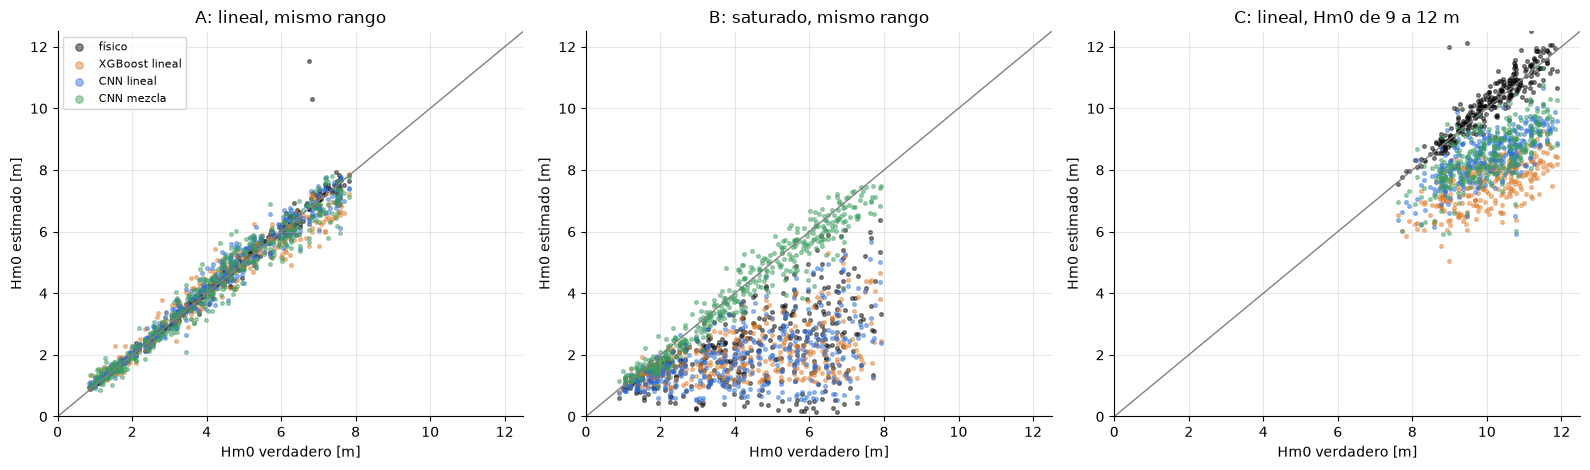

In [7]:
def tabla_test(d, nombre):
    filas = {"físico (inversión por |T|²)": metricas(d["fis"], d["y"]),
             "XGBoost, entrenado lineal": metricas(predice_xgb(xgb_lin, d), d["y"]),
             "XGBoost, entrenado con mezcla": metricas(predice_xgb(xgb_mez, d), d["y"])}
    for etiqueta, lista in [("CNN, entrenada lineal", cnn_lin), ("CNN, entrenada con mezcla", cnn_mez)]:
        ms = pd.DataFrame([metricas(predice_cnn(m, cj, d), d["y"]) for m, cj in lista])
        filas[etiqueta] = {**ms.mean().to_dict(), "desv. semillas, Hm0 error [%]": ms["Hm0 error medio [%]"].std()}
    t = pd.DataFrame(filas).T
    t.index = pd.MultiIndex.from_product([[nombre], t.index])
    return t

TABLAS = {n: tabla_test(d, n) for n, d in [("A lineal", t_lin), ("B saturado", t_sat), ("C Hm0 9-12 m", t_gra)]}
for n, t in TABLAS.items(): display(t.round(2))

# Figura: Hm0 estimado frente a Hm0 verdadero en los tres test
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
series = [("físico", "k", lambda d: d["fis"][:, 0]), ("XGBoost lineal", "#e07b28", lambda d: predice_xgb(xgb_lin, d)[:, 0]),
          ("CNN lineal", "#2a6fdb", lambda d: predice_cnn(*cnn_lin[0], d)[:, 0]), ("CNN mezcla", "#3a9d5d", lambda d: predice_cnn(*cnn_mez[0], d)[:, 0])]
for a_, (n, d) in zip(axs, [("A: lineal, mismo rango", t_lin), ("B: saturado, mismo rango", t_sat), ("C: lineal, Hm0 de 9 a 12 m", t_gra)]):
    for lab, col, f_ in series: a_.scatter(d["y"][:, 0], f_(d), s=7, alpha=0.45, color=col, label=lab)
    lim = [0, 12.5]; a_.plot(lim, lim, "grey", lw=1); a_.set(xlabel="Hm0 verdadero [m]", ylabel="Hm0 estimado [m]", title=n, xlim=lim, ylim=lim)
axs[0].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

**Lectura.**

* **A, lineal y en rango: el método físico gana en altura y las máquinas en periodo y dirección.** El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost. En $T_p$ y dirección pasa lo contrario: XGBoost 0,23 s y 1,0°, CNN 0,5 s y 1,35°, físico 1,1 s y 3,7°, porque el método físico toma el máximo de una malla de números de onda gruesa. **La CNN no mejora a XGBoost en ninguna de las tres magnitudes en este test.**
* **B, con saturación: todo lo entrenado o razonado en régimen lineal falla igual.** La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %: dividir por $|T|^2$, o aprenderlo, sobrestima la modulación que debería tener la ola. Las variantes **mezcla** lo corrigen (sesgo de −2,5 % y −3,1 %), porque el simulador ya contiene el efecto. Aquí la CNN mezcla es algo mejor que XGBoost mezcla en altura (RMSE de 0,49 m frente a 0,62 m) y algo peor en periodo (0,52 s frente a 0,40 s), con la misma dirección (1,8°). La ventaja existe pero es pequeña, y es la única de la tabla.
* **C, olas más altas que las vistas: gana el método físico.** Se mantiene con un error de 4,8 %, mientras que XGBoost (−24 %) y la CNN (−16 a −18 %) se quedan por debajo del máximo de entrenamiento. Es el mismo fallo de extrapolación que vimos en el cuaderno 04: las redes y los árboles no extrapolan, y una ecuación física sí.
* **Qué se aprende:** el aprendizaje automático solo corrige lo que el simulador contiene; la física corrige lo que la ecuación contiene. Cada uno falla cuando se sale de lo suyo. Una CNN no es "mejor", es **otra forma de codificar un modelo**, y su fiabilidad la fija el simulador (o las etiquetas reales) con el que se entrena.


## 5. Aplicación a las 8 viñetas reales

**No hay verdad real.** No existe ninguna medida independiente de estas viñetas, así que aquí solo podemos medir si los métodos **coinciden entre sí** y si la entrada real se parece a la simulada. Que la CNN entrenada con nuestra simulación coincida con nuestro método físico es de esperar: ambos comparten el mismo modelo de formación de imagen. Una discrepancia, en cambio, es informativa: señala dónde el simulador se aleja de la realidad (**brecha sim-a-real**).

,Hm0 físico [m],Hm0 XGB-lin,Hm0 CNN-lin,Hm0 CNN-mezcla,Tp físico [s],Tp CNN-lin,Tp CNN-mezcla,dir físico [°],dir CNN-lin [°],dir CNN-mezcla [°]
viñeta,,,,,,,,,,
20160501 2100,6.9,3.0,3.0,10.1,16.8,16.200001,14.2,120.3,110.6,108.4
20161127 0410,1.0,1.4,0.8,5.2,20.5,15.800000,12.2,90.8,39.2,21.7
20160614 1020,5.9,2.8,3.0,9.9,14.9,16.100000,13.9,82.0,75.2,75.0
20160127 1616,3.7,2.2,2.1,8.9,12.2,16.400000,13.9,109.4,100.1,96.5
20161010 1804,4.4,2.4,2.1,8.6,13.2,14.500000,12.8,110.8,103.4,103.2
20161224 2210,1.7,1.7,1.0,5.7,20.7,14.800000,11.9,120.6,80.0,66.4
20160108 0717,2.5,1.4,1.1,3.8,13.2,13.700000,11.8,68.2,71.0,77.0
20160325 0053,3.1,1.8,1.3,4.6,13.8,15.200000,12.7,72.5,71.8,71.5


,Hm0: cociente mediano CNN/físico,Hm0: correlación con el físico,Tp: diferencia media [s],dirección: diferencia media [°]
CNN entrenada lineal,0.49,0.97,2.49,16.11
CNN entrenada con mezcla,1.82,0.84,3.17,21.55


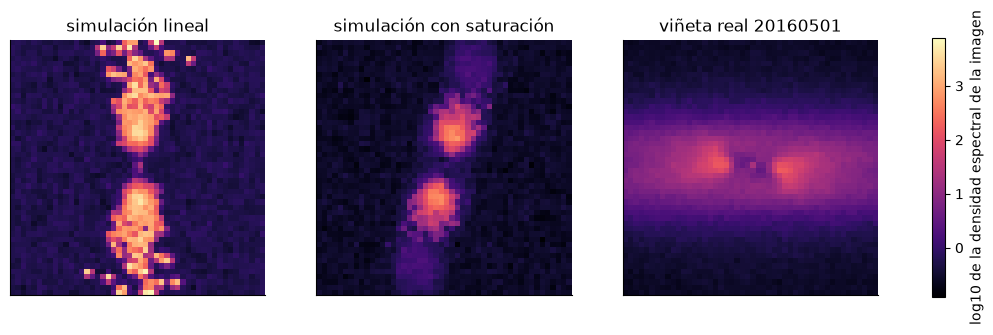

In [8]:
# --- Viñetas reales: entradas, y comparación con el método físico (NO hay verdad real) ---
REALES = [espectro_sar(i["a"], i["ec"], i["er"], i["sub"], i["lon"], i["lat"]) for i in IMG]
d_real = dict(x=np.stack([entrada_cnn(R) for R in REALES]), sub=np.array([float(i["sub"] == "wv2") for i in IMG], np.float32),
              rasgos=np.stack([rasgos_cwave(R) for R in REALES]), y=np.tile([[1.0, 10.0, 0.0]], (len(IMG), 1)))

def predice_cnn_conjunto(lista, d):
    # Media de las salidas (en el espacio codificado) de las 3 semillas
    cj = lista[0][1]; X, _ = cj.tensores(d)
    with torch.no_grad(): p = np.mean([m(X).numpy() for m, _ in lista], 0)
    return cj.inversa(p)

def a_brujula(psi_marco, R):
    # Dirección "desde" en el marco de la imagen (columnas = x, filas = y) -> procedencia respecto al norte verdadero (módulo 180°)
    a_ = np.deg2rad(psi_marco + 180)
    kE, kN = vector_geo(np.sin(a_), np.cos(a_), R)
    return (np.rad2deg(np.arctan2(kE, kN)) + R["gam"] + 180) % 180

fis = [metodo_fisico(R) for R in REALES]
p_lin, p_mez, p_xl, p_xm = (predice_cnn_conjunto(cnn_lin, d_real), predice_cnn_conjunto(cnn_mez, d_real),
                            predice_xgb(xgb_lin, d_real), predice_xgb(xgb_mez, d_real))
filas = []
for k, (im, R) in enumerate(zip(IMG, REALES)):
    filas.append({"viñeta": f"{im['hora'][:8]} {im['hora'][9:13]}", "Hm0 físico [m]": fis[k]["Hm0"], "Hm0 XGB-lin": p_xl[k, 0], "Hm0 CNN-lin": p_lin[k, 0],
                  "Hm0 CNN-mezcla": p_mez[k, 0], "Tp físico [s]": fis[k]["Tp"], "Tp CNN-lin": p_lin[k, 1], "Tp CNN-mezcla": p_mez[k, 1],
                  "dir físico [°]": fis[k]["desde"] % 180, "dir CNN-lin [°]": a_brujula(p_lin[k, 2], R), "dir CNN-mezcla [°]": a_brujula(p_mez[k, 2], R)})
real_tab = pd.DataFrame(filas).set_index("viñeta")
display(real_tab.round(1))
cmp_ = pd.DataFrame({
    "Hm0: cociente mediano CNN/físico": [np.median(p_lin[:, 0] / [f["Hm0"] for f in fis]), np.median(p_mez[:, 0] / [f["Hm0"] for f in fis])],
    "Hm0: correlación con el físico": [np.corrcoef(p_lin[:, 0], [f["Hm0"] for f in fis])[0, 1], np.corrcoef(p_mez[:, 0], [f["Hm0"] for f in fis])[0, 1]],
    "Tp: diferencia media [s]": [np.mean(np.abs(p_lin[:, 1] - [f["Tp"] for f in fis])), np.mean(np.abs(p_mez[:, 1] - [f["Tp"] for f in fis]))],
    "dirección: diferencia media [°]": [np.mean(error_dir(real_tab["dir CNN-lin [°]"], real_tab["dir físico [°]"])),
                                         np.mean(error_dir(real_tab["dir CNN-mezcla [°]"], real_tab["dir físico [°]"]))]},
    index=["CNN entrenada lineal", "CNN entrenada con mezcla"])
display(cmp_.round(2))

# Brecha sim-a-real: espectros de entrada (log10) de una escena lineal, una saturada y una viñeta real
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
c0 = [d_lin["x"][3], d_sat["x"][3], d_real["x"][0]]; vmin, vmax = min(c.min() for c in c0), max(c.max() for c in c0)
for a_, c, tit in zip(axs, c0, ["simulación lineal", "simulación con saturación", f"viñeta real {IMG[0]['hora'][:8]}"]):
    pc = a_.imshow(c, origin="lower", cmap="magma", vmin=vmin, vmax=vmax); a_.grid(False); a_.set(title=tit, xticks=[], yticks=[])
fig.colorbar(pc, ax=axs, shrink=0.8).set_label("log10 de la densidad espectral de la imagen")
plt.show()

**Lectura.**

* **La entrada real no se parece del todo a la simulada.** En la figura, el espectro real tiene un fondo ancho y difuso a lo largo del eje de acimut que ninguna de las dos simulaciones reproduce. Es una **brecha sim-a-real** visible antes de mirar ningún resultado.
* **La altura depende de qué física se supone.** Con la CNN entrenada solo con escenas lineales sale la mitad que con el método físico (cociente mediano 0,49, correlación 0,97). Con la CNN entrenada con la mezcla sale 1,9 veces más (correlación 0,86). Para la primera viñeta, 7 m del método físico, 3,0 m y 10,7 m de las dos CNN: un factor 3,5 entre las dos redes. El **orden** de las viñetas se conserva, pero el **valor absoluto** de $H_{m0}$ es el parámetro menos determinado de todo el cuaderno, justamente lo que necesita una referencia independiente.
* **Periodo y dirección:** las CNN comprimen $T_p$ hacia 12 a 16 s y no llegan a los 20 s del método físico en las viñetas 2 y 6 (15,8 s y 14,8 s con la CNN lineal), lo que seguramente refleja que son pocas las celdas de número de onda para periodos largos. La dirección coincide con el método físico dentro de unos 10° en seis de las ocho viñetas y falla en dos, en las que ha difuminado el pico (por ejemplo, 41° frente a 91° en la viñeta 2). Sin una referencia no podemos decir cuál de los dos tiene razón.
* **Conclusión de esta parte:** nada de lo que se ve aquí valida ni invalida los métodos con el mar real. Solo mide qué tan sensibles son al modelo que suponemos.


## 6. Mar real en un solo sitio, con ERA5 como referencia

Hasta aquí todo era simulado o sin verdad. Ahora comparamos con el reanálisis **ERA5** (ECMWF, Copernicus) en **un único punto del océano**, para poder seguir una serie temporal de un solo lugar.

**Cómo elegí el sitio.** De la clase F de TenGeoP-SARwv ("Pure Ocean Waves", sin hielo, tierra, frentes ni células de lluvia, es decir, **sin obstrucciones**; el radar además ve a través de las nubes) busqué la zona de 2016 con más imágenes en un radio de 600 km: el Pacífico sur frente a Chile, centrado en **55°S 90°W**, con **193 imágenes** en el año. Es oleaje oceánico abierto y fuerte, sin costa cerca, y las imágenes llegan en grupos de pasadas, que dan una buena serie temporal.

**Estado de esta sección.** Las subsecciones 6.1 a 6.4 son el **piloto de enero de 2016 (8 imágenes)**, que se conserva porque enseña qué falla y por qué hacen falta más datos. Las subsecciones 6.5 a 6.10 repiten y amplían todo con **187 imágenes de 10 meses de 2016**.

**Datos.** Imágenes de TenGeoP-SARwv ([Wang et al., 2019](https://doi.org/10.1002/gdj3.73), [SEANOE](https://www.seanoe.org/data/00456/56796/) (repositorio francés de datos científicos oceánicos abiertos), licencia CC BY-NC-SA 4.0; solo para uso no comercial) y ERA5 interpolado a la posición y la hora de cada imagen (bilineal en el espacio y lineal en el tiempo). Contiene información de Copernicus Climate Change Service.

8 imágenes; 20160119t014117 a 20160130t103430 UTC


,hora,lat,lon,Hs total [m],Hs swell [m],Tp total [s],T medio swell [s],dir. swell desde [°]
0,20160119t014117,-56.7,-98.0,2.7,2.6,9.3,8.9,283.8
1,20160128t011647,-56.0,-92.3,3.8,3.5,10.9,9.8,292.4
2,20160128t011717,-54.3,-93.4,3.8,3.6,10.7,9.8,289.8
3,20160129t113135,-52.7,-97.7,5.1,2.8,9.1,11.2,252.8
4,20160130t010041,-54.8,-88.9,4.5,4.1,10.7,10.2,307.3
5,20160130t010110,-53.1,-90.0,4.4,4.3,10.8,10.0,304.1
6,20160130t010209,-49.7,-91.8,4.7,3.1,10.8,11.0,272.8
7,20160130t103430,-54.5,-84.4,4.0,3.7,11.1,10.4,299.2


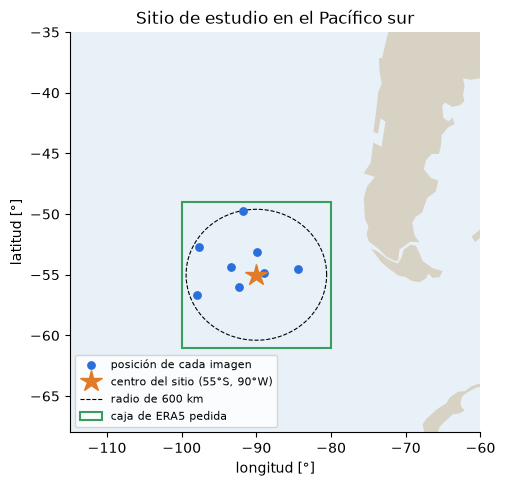

In [9]:
# Imágenes del sitio (enteros de 16 bits + geometría) y valores de ERA5 en cada imagen
zs = np.load(DATOS / "sar_sitio_2016.npz")
meta_s = json.loads(str(zs["meta"]))
SITIO = [dict(a=zs[f"img{k}"].astype(float) * 4.5777065690089265e-05, ec=zs[f"ec{k}"], er=zs[f"er{k}"], **m) for k, m in enumerate(meta_s)]
ERA = pd.read_csv(DATOS / "era5_sitio_2016.csv")
print(len(SITIO), "imágenes;", ERA["hora"].min(), "a", ERA["hora"].max(), "UTC")
display(ERA[["hora", "lat", "lon", "swh", "shts", "pp1d", "mpts", "mdts"]].rename(columns={
    "swh": "Hs total [m]", "shts": "Hs swell [m]", "pp1d": "Tp total [s]", "mpts": "T medio swell [s]", "mdts": "dir. swell desde [°]"}).round(1))

# Mapa: costa (Natural Earth, dominio público), el sitio y la posición de cada imagen
tierra = json.load(open(DATOS / "ne_110m_land.geojson"))
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for f_ in tierra["features"]:
    g = f_["geometry"]; polis = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    for p_ in polis: ax.fill(*np.array(p_[0]).T, color="#d8d2c4", lw=0)
ax.scatter(ERA["lon"], ERA["lat"], s=28, color="#2a6fdb", zorder=3, label="posición de cada imagen")
ax.plot(-90, -55, "*", ms=16, color="#e07b28", zorder=4, label="centro del sitio (55°S, 90°W)")
t_ = np.linspace(0, 2 * np.pi, 200); ax.plot(-90 + 600 / (111.2 * np.cos(np.deg2rad(55))) * np.cos(t_), -55 + 600 / 111.2 * np.sin(t_), "k--", lw=0.8, label="radio de 600 km")
ax.add_patch(plt.Rectangle((-100, -61), 20, 12, fill=False, ec="#3a9d5d", lw=1.5, label="caja de ERA5 pedida"))
ax.set(xlim=(-115, -60), ylim=(-68, -35), xlabel="longitud [°]", ylabel="latitud [°]", title="Sitio de estudio en el Pacífico sur", aspect=1 / np.cos(np.deg2rad(52)))
ax.legend(fontsize=8, loc="lower left"); ax.set_facecolor("#e8f1f7"); ax.grid(False); plt.show()


### 6.1 Cómo se ven las imágenes

Cada imagen es una viñeta de Sentinel-1 en modo oleaje, de unos 20 × 20 km. La intensidad cruda es sobre todo *speckle* (ruido multiplicativo del radar). Para ver el oleaje hacemos lo mismo que el método físico: **dividimos por la intensidad local** (filtro gaussiano de 15 píxeles) y restamos 1, y para la figura suavizamos 2 píxeles para atenuar el *speckle*. Lo que queda son bandas claras y oscuras: crestas de oleaje que la modulación del radar hace visibles.

El eje horizontal es el **alcance** (dirección en que el radar mira, perpendicular a la trayectoria del satélite) y el vertical el **acimut** (a lo largo de la trayectoria). Esto importa más abajo.

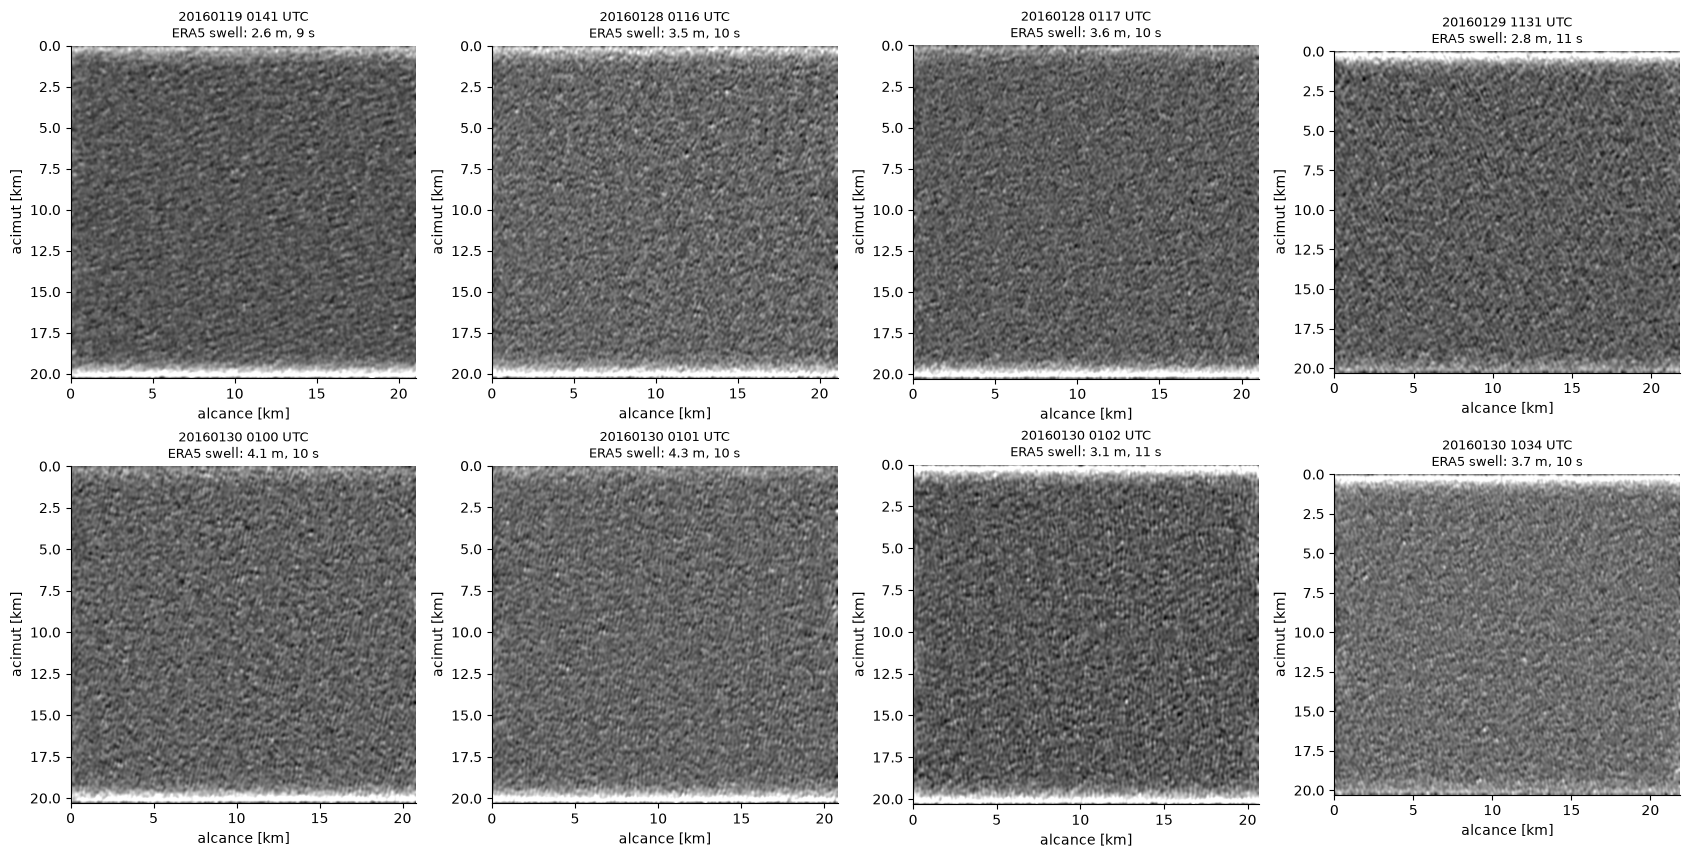

In [10]:
def imagen_normalizada(a, suave=2):
    return ndimage.gaussian_filter(a / ndimage.gaussian_filter(a, 15, mode="nearest") - 1, suave)

fig, axs = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, im, (_, e) in zip(axs.ravel(), SITIO, ERA.iterrows()):
    H, W = im["a"].shape; dc, dr = np.linalg.norm(im["ec"]), np.linalg.norm(im["er"])
    ax.imshow(np.clip(imagen_normalizada(im["a"]), -0.3, 0.3), cmap="gray", extent=[0, W * dc / 1e3, H * dr / 1e3, 0]); ax.grid(False)
    ax.set_title(f"{im['hora'][:8]} {im['hora'][9:13]} UTC\nERA5 swell: {e['shts']:.1f} m, {e['mpts']:.0f} s", fontsize=9)
    ax.set(xlabel="alcance [km]", ylabel="acimut [km]")
plt.tight_layout(); plt.show()


### 6.2 Leer el análisis sobre las imágenes

La figura siguiente reúne cuatro imágenes de enero. **Fila de arriba**, la imagen normalizada con dos marcas:

* **Línea amarilla con dos puntas**: la dirección del oleaje que estima el método físico. Tiene dos puntas porque una imagen de intensidad **no distingue el sentido** (ambigüedad de 180°).
* **Flecha azul**: hacia dónde va el swell según ERA5 (la dirección `mdts` de ERA5 es *desde dónde* viene, así que la flecha apunta 180° más allá).

**Fila de abajo**, el espectro 2D del mismo método, ya corregido por la función de transferencia, con los números de onda de alcance en horizontal y de acimut en vertical. Los círculos amarillos son los dos picos (simétricos) que usa el método; la línea azul discontinua es la dirección de ERA5 en ese mismo plano; los círculos de puntos son las longitudes de onda de 100 y 800 m, los límites del método.

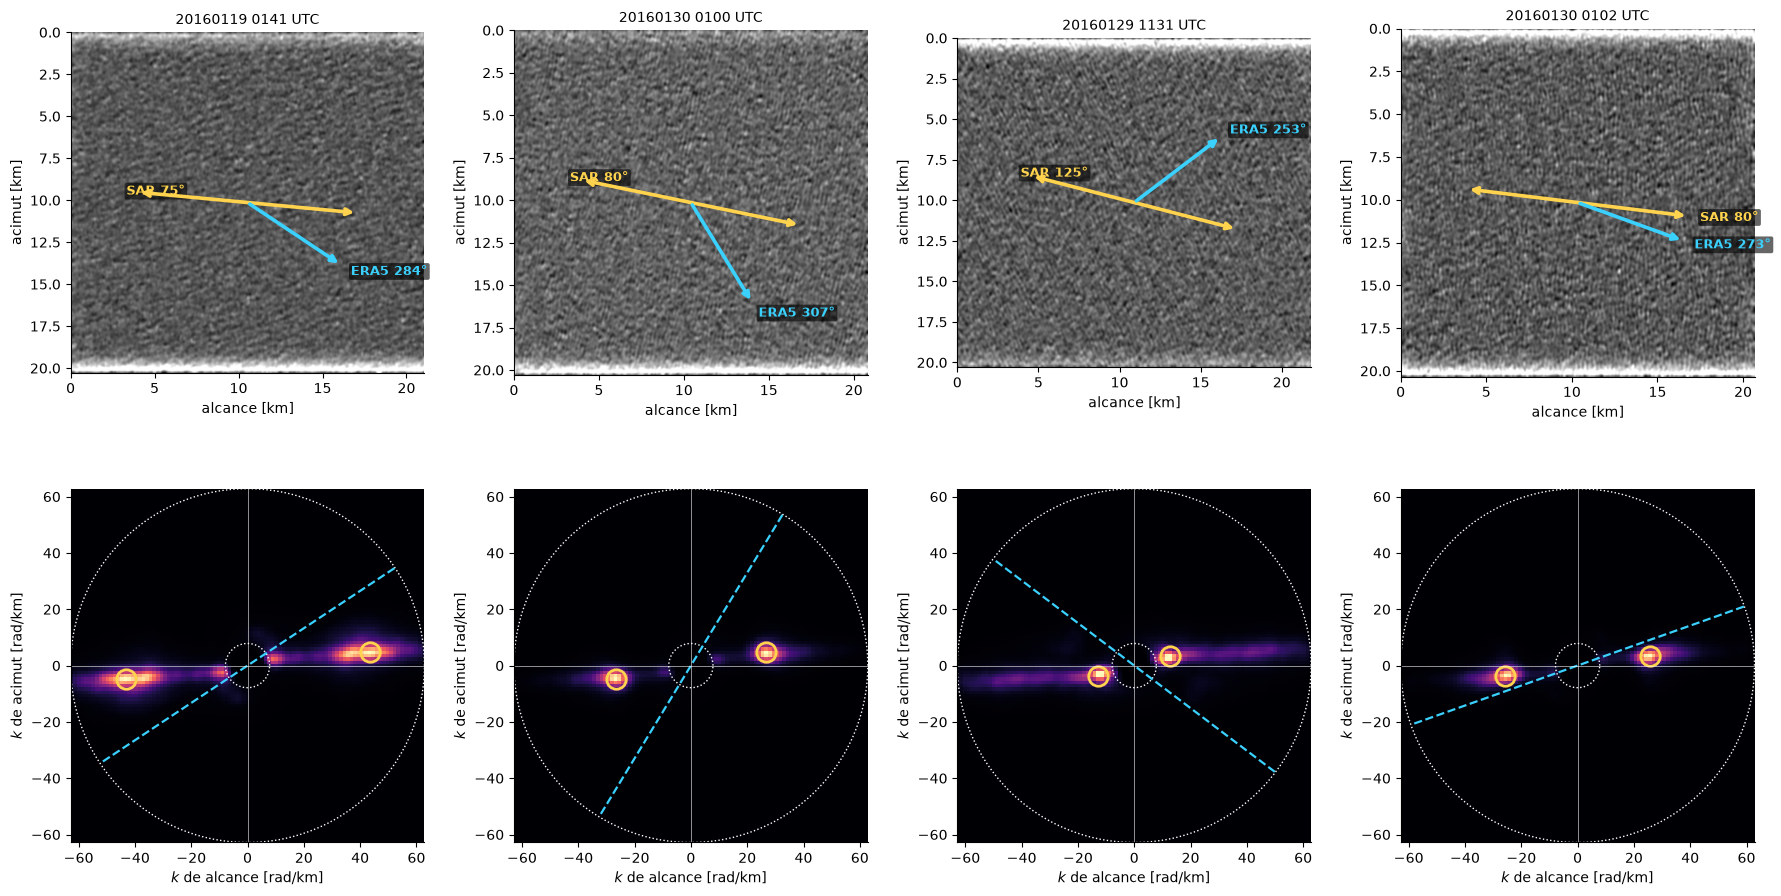

In [11]:
def a_pixeles(vE, vN, ec, er):
    # vector geográfico (E, N) -> componentes (columna, fila); ec, er = metros (E, N) por pixel de columna y de fila
    return np.linalg.solve(np.array([[ec[0], er[0]], [ec[1], er[1]]]), [vE, vN])

def unit_pix(desde_deg, ec, er, hacia=True):
    a_ = np.deg2rad(desde_deg + (180 if hacia else 0)); v = a_pixeles(np.sin(a_), np.cos(a_), ec, er); return v / np.hypot(*v)

def panel_anotado(ax_im, ax_sp, im, e):
    a, ec, er = im["a"], im["ec"], im["er"]; H, W = a.shape; dc, dr = np.linalg.norm(ec), np.linalg.norm(er)
    R = espectro_sar(a, ec, er, im["sub"], im["lon"], im["lat"]); f = metodo_fisico(R)
    km = lambda v: v * np.array([dc, dr]) / 1e3; c0 = np.array([W / 2, H / 2])
    ax_im.imshow(np.clip(imagen_normalizada(a), -0.3, 0.3), cmap="gray", extent=[0, W * dc / 1e3, H * dr / 1e3, 0]); ax_im.grid(False)
    ax_im.set_title(f"{im['hora'][:8]} {im['hora'][9:13]} UTC", fontsize=10); ax_im.set(xlabel="alcance [km]", ylabel="acimut [km]")
    v = unit_pix(f["desde"], ec, er)
    ax_im.annotate("", xy=km(c0 + v * 170), xytext=km(c0 - v * 170), arrowprops=dict(arrowstyle="<->", color="#ffd34d", lw=2.6), zorder=5)
    ax_im.text(*km(c0 + v * 188), f"SAR {f['desde'] % 180:.0f}°", color="#ffd34d", fontsize=9, weight="bold", va="center",
               bbox=dict(boxstyle="round,pad=0.15", fc="black", ec="none", alpha=0.6))
    v = unit_pix(e["mdts"], ec, er)
    ax_im.annotate("", xy=km(c0 + v * 170), xytext=km(c0), arrowprops=dict(arrowstyle="-|>", color="#3ad1ff", lw=2.6), zorder=5)
    ax_im.text(*km(c0 + v * 188), f"ERA5 {e['mdts'] % 360:.0f}°", color="#3ad1ff", fontsize=9, weight="bold", va="center",
               bbox=dict(boxstyle="round,pad=0.15", fc="black", ec="none", alpha=0.6))
    kk, lim = 1e3, 2 * np.pi / 100 * 1e3; Fs = ndimage.gaussian_filter(R["F"], 1)
    ax_sp.pcolormesh(R["kc"] * kk, R["kr"] * kk, Fs, cmap="magma", shading="auto"); ax_sp.grid(False); ax_sp.set_aspect("equal")
    ax_sp.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="$k$ de alcance [rad/km]", ylabel="$k$ de acimut [rad/km]")
    t_ = np.linspace(0, 2 * np.pi, 200)
    for lam in (100, 800): ax_sp.plot(2 * np.pi / lam * kk * np.cos(t_), 2 * np.pi / lam * kk * np.sin(t_), "w:", lw=1)
    ecu, eru = ec / dc, er / dr; ar = np.deg2rad(e["mdts"]); kE, kN = np.sin(ar), np.cos(ar)
    d = np.array([kE * ecu[0] + kN * ecu[1], kE * eru[0] + kN * eru[1]])
    ax_sp.plot([-lim * d[0], lim * d[0]], [-lim * d[1], lim * d[1]], "--", color="#3ad1ff", lw=1.6)
    i = np.unravel_index(Fs.argmax(), Fs.shape)
    for s_ in (1, -1): ax_sp.plot(s_ * R["KC"][i] * kk, s_ * R["KR"][i] * kk, "o", mfc="none", mec="#ffd34d", ms=14, mew=2)
    ax_sp.axhline(0, color="w", lw=0.4); ax_sp.axvline(0, color="w", lw=0.4)
    return f, R

ELEGIDAS = [0, 4, 3, 6]
fig, axs = plt.subplots(2, 4, figsize=(18, 9.6))
for c, k in enumerate(ELEGIDAS): panel_anotado(axs[0, c], axs[1, c], SITIO[k], ERA.iloc[k])
plt.tight_layout(); plt.show()

**Lectura.**

* **La energía del SAR se alinea con la dirección de alcance, no con la del oleaje.** En la fila de abajo los dos picos amarillos están siempre pegados al eje horizontal (número de onda de acimut casi cero), aunque la línea azul de ERA5 apunte a otro lado. En las cuatro imágenes, la dirección que sale es casi la del eje de alcance (entre 75° y 125°, según la orientación de la pasada), y en la fila de arriba la línea amarilla es siempre casi horizontal.
* **Por qué puede ocurrir (explicación habitual, no demostrada aquí).** El radar ve bien las olas que viajan en alcance, porque la inclinación de la superficie modula la señal. Las que viajan hacia el acimut dependen del agrupamiento por velocidad, que además emborrona las franjas cortas (corte en acimut) y satura la modulación. El método divide por $|T|^2$ para compensarlo, pero es un modelo cuasi-lineal y con modulación saturada no recupera esa parte.
* **Una imagen distinta.** En la tercera, ERA5 da un swell que viene de 253°, pero la dirección media del mar total (`mwd`) es de 130° módulo 180°, cerca de los 125° del SAR: hay dos sistemas de olas a la vez y el método físico se queda con uno solo.


### 6.3 Método físico frente a ERA5 (enero, 8 imágenes)

Comparamos con lo que el SAR puede ver: el **swell** de ERA5 (`shts`, `mpts`, `mdts`), porque el mar de viento corto (menos de 100 m) es invisible para el radar. Para el periodo se usa el periodo medio del swell, que es lo que ERA5 da para el swell.

,Hm0 SAR [m],Hs swell ERA5 [m],Tp SAR [s],T swell ERA5 [s],dir SAR [°],dir swell ERA5 [°],eje de alcance [°]
imagen,,,,,,,
20160119 0141,2.2,2.6,9.6,8.9,75.4,103.8,70.0
20160128 0116,2.6,3.5,20.9,9.8,84.4,112.4,70.1
20160128 0117,2.3,3.6,13.2,9.8,79.0,109.8,69.9
20160129 1131,2.2,2.8,17.4,11.2,124.6,72.8,110.1
20160130 0100,3.2,4.1,12.2,10.2,80.1,127.3,68.4
20160130 0101,3.4,4.3,12.5,10.0,78.7,124.1,68.4
20160130 0102,3.5,3.1,12.5,11.0,79.8,92.8,72.8
20160130 1034,2.9,3.7,17.6,10.4,120.4,119.2,112.0


dirección: error angular medio 30.7 °; mediano 29.6 °


,sesgo,RMSE,correlación
altura Hm0 frente a Hs swell [m],-0.68,0.83,0.60
periodo Tp frente a T medio swell [s],4.31,5.44,0.36


referencia sin SAR (predecir siempre la media de las otras 7), RMSE de altura: 0.64 m


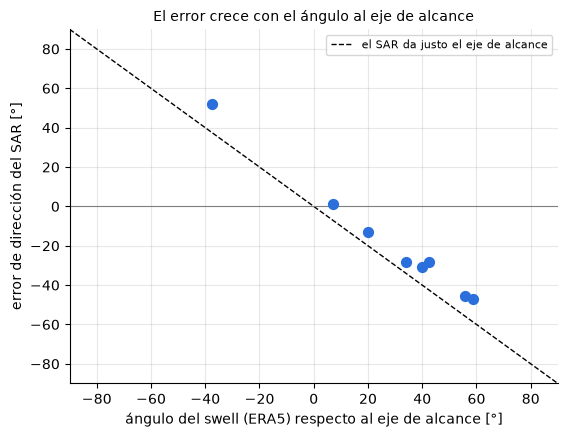

In [12]:
filas, REAL_ESP = [], []
for im, (_, e) in zip(SITIO, ERA.iterrows()):
    R = espectro_sar(im["a"], im["ec"], im["er"], im["sub"], im["lon"], im["lat"]); f = metodo_fisico(R); REAL_ESP.append(R)
    eje_alcance = np.rad2deg(np.arctan2(*im["ec"])) % 180                  # dirección geográfica del eje de alcance, módulo 180°
    filas.append({"imagen": f"{im['hora'][:8]} {im['hora'][9:13]}", "Hm0 SAR [m]": f["Hm0"], "Hs swell ERA5 [m]": e["shts"],
                  "Tp SAR [s]": f["Tp"], "T swell ERA5 [s]": e["mpts"], "dir SAR [°]": f["desde"] % 180, "dir swell ERA5 [°]": e["mdts"] % 180,
                  "eje de alcance [°]": eje_alcance})
VAL = pd.DataFrame(filas).set_index("imagen"); display(VAL.round(1))

def resumen(p, t): return dict(sesgo=np.mean(p - t), RMSE=np.sqrt(np.mean((p - t) ** 2)), correlación=np.corrcoef(p, t)[0, 1])
tab_val = pd.DataFrame({
    "altura Hm0 frente a Hs swell [m]": resumen(VAL["Hm0 SAR [m]"], VAL["Hs swell ERA5 [m]"]),
    "periodo Tp frente a T medio swell [s]": resumen(VAL["Tp SAR [s]"], VAL["T swell ERA5 [s]"])}).T
err_dir = error_dir(VAL["dir SAR [°]"], VAL["dir swell ERA5 [°]"])
print("dirección: error angular medio", round(float(np.mean(err_dir)), 1), "°; mediano", round(float(np.median(err_dir)), 1), "°")
display(tab_val.round(2))
print("referencia sin SAR (predecir siempre la media de las otras 7), RMSE de altura:",
      round(float(np.sqrt(np.mean([(VAL["Hs swell ERA5 [m]"].iloc[k] - VAL["Hs swell ERA5 [m]"].drop(VAL.index[k]).mean()) ** 2 for k in range(len(VAL))]))), 2), "m")

# Error de dirección frente al ángulo entre el oleaje y el eje de alcance
alc = VAL["eje de alcance [°]"].values; era_d = VAL["dir swell ERA5 [°]"].values; sar_d = VAL["dir SAR [°]"].values
dif = lambda a, b: (a - b + 90) % 180 - 90
fig, ax = plt.subplots(figsize=(6.3, 4.6))
ax.scatter(dif(era_d, alc), dif(sar_d, era_d), s=50, color="#2a6fdb", zorder=3)
x_ = np.linspace(-90, 90, 3); ax.plot(x_, -x_, "k--", lw=1, label="el SAR da justo el eje de alcance")
ax.axhline(0, color="grey", lw=0.8); ax.set(xlabel="ángulo del swell (ERA5) respecto al eje de alcance [°]", ylabel="error de dirección del SAR [°]", xlim=(-90, 90), ylim=(-90, 90))
ax.set_title("El error crece con el ángulo al eje de alcance", fontsize=10); ax.legend(fontsize=8); plt.show()

**Lectura (8 imágenes, unas 4 independientes: léelo como piloto, no como medida).**

* **Altura.** Sesgo de **-0,68 m** (el SAR da un 19 % menos), RMSE de 0,83 m y correlación de 0,60. Es **peor que predecir siempre la media** de las otras siete imágenes (0,64 m): por ahora el método físico no aporta nada sobre la climatología de este mes. El sesgo negativo es el esperable con modulación saturada, y es lo bastante constante como para poder corregirse con una regresión cuando haya más datos.
* **Periodo.** Sesgo de **+4,3 s** y correlación de 0,36. En 5 de las 8 imágenes el pico sale entre 12 y 21 s, frente a unos 10 s de ERA5. Probablemente el máximo del espectro, tras dividir por $|T|^2$, recoge ruido de números de onda bajos, donde $|T|^2$ es pequeño. Un periodo medio del espectro, en vez del máximo, debería comportarse mejor.
* **Dirección.** Error medio de **31°**. En el gráfico, seis de las ocho imágenes quedan cerca de la recta discontinua: el error del SAR es casi exactamente el ángulo que separa el oleaje del eje de alcance, es decir, el método devuelve el eje de alcance. El punto aislado de arriba a la izquierda es la imagen con dos sistemas de olas. Solo hay dos orientaciones de pasada (eje de alcance a unos 70° y a unos 110°), así que con enero no se puede separar el efecto del instrumento del de la dirección real del swell; con más meses sí.


### 6.4 Piloto de la CNN con las 8 imágenes

Para ver si merece la pena seguir, entrenamos una CNN pequeña **solo con las imágenes reales de enero** y las etiquetas de ERA5. Cada imagen da 6 recortes de 256 × 256 píxeles (con solapamiento), 48 en total; las etiquetas son el $H_s$ del swell y el periodo medio del swell. Se valida **dejando una imagen fuera cada vez** (los 6 recortes de una imagen van juntos, para no hacer trampa con recortes vecinos). La referencia a batir es predecir siempre la media de las demás.

In [13]:
t_pil = time.time(); torch.manual_seed(0)
Xp, Sp, Yp, Gp = [], [], [], []
for g, (im, (_, e)) in enumerate(zip(SITIO, ERA.iterrows())):
    a = im["a"]; Hh, Ww = a.shape
    for i in range(0, Hh - 255, 128):
        for j in range(0, Ww - 255, 128):
            Rc = espectro_sar(a[i:i + 256, j:j + 256], im["ec"], im["er"], im["sub"], im["lon"], im["lat"])
            Xp.append(entrada_cnn(Rc)); Sp.append(float(im["sub"] == "wv2")); Yp.append([np.log(e["shts"]), e["mpts"]]); Gp.append(g)
Xp, Sp, Yp, Gp = np.array(Xp), np.array(Sp, np.float32), np.array(Yp, np.float32), np.array(Gp)

class CNNPiloto(nn.Module):
    def __init__(s):
        super().__init__()
        s.c = nn.Sequential(nn.Conv2d(2, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(2), nn.Flatten())
        s.h = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 2))
    def forward(s, x): return s.h(s.c(x))

def tensores_p(X, S, mu, sd):
    x = torch.from_numpy(((X - mu) / sd)[:, None]).float(); return torch.cat([x, torch.from_numpy(S)[:, None, None, None].expand(-1, 1, MEDIO, MEDIO)], 1)

pred_p = np.zeros_like(Yp)
for k in range(len(SITIO)):
    tr, te = Gp != k, Gp == k; mu, sd = Xp[tr].mean(), Xp[tr].std(); ym, ys = Yp[tr].mean(0), Yp[tr].std(0) + 1e-6
    m = CNNPiloto(); opt = torch.optim.Adam(m.parameters(), 1e-3, weight_decay=1e-3)
    xt, yt = tensores_p(Xp[tr], Sp[tr], mu, sd), torch.from_numpy((Yp[tr] - ym) / ys)
    for ep in range(60):
        m.train(); perm = torch.randperm(len(xt))
        for b in range(0, len(perm), 16):
            i = perm[b:b + 16]; opt.zero_grad(); nn.functional.mse_loss(m(xt[i]), yt[i]).backward(); opt.step()
    m.eval()
    with torch.no_grad(): pred_p[te] = m(tensores_p(Xp[te], Sp[te], mu, sd)).numpy() * ys + ym
pi_p = np.array([pred_p[Gp == k].mean(0) for k in range(len(SITIO))]); ti_p = np.array([Yp[Gp == k][0] for k in range(len(SITIO))])
r_cnn = pd.DataFrame({"altura Hs swell [m]": resumen(np.exp(pi_p[:, 0]), np.exp(ti_p[:, 0])), "periodo medio del swell [s]": resumen(pi_p[:, 1], ti_p[:, 1])}).T
display(r_cnn.round(2))
print("Hs swell de ERA5 por imagen:", np.exp(ti_p[:, 0]).round(1)); print("Hs predicho por la CNN:      ", np.exp(pi_p[:, 0]).round(1))
print(f"{len(Xp)} recortes de {len(SITIO)} imágenes, 8 entrenamientos, {time.time() - t_pil:.0f} s")

,sesgo,RMSE,correlación
altura Hs swell [m],0.03,0.67,-0.40
periodo medio del swell [s],-0.07,0.70,0.21


Hs swell de ERA5 por imagen: [2.6 3.5 3.6 2.8 4.1 4.3 3.1 3.7]
Hs predicho por la CNN:       [3.8 3.7 3.3 3.5 3.5 3.5 3.5 3.1]
48 recortes de 8 imágenes, 8 entrenamientos, 5 s


**Lectura.**

* **La CNN no aprende nada útil con 8 imágenes.** Predice casi siempre entre 3,3 y 3,8 m, su RMSE (0,67 m) iguala al de la referencia de la media (0,64 m) y la correlación es negativa. Era lo esperable: tiene unos 6 000 parámetros y solo unas 4 imágenes independientes. No es evidencia de que la CNN sea mala en esta tarea, solo de que con este tamaño no se puede saber.
* **Lo que sí valida el piloto.** La tubería completa funciona: imagen, recortes, espectro, etiquetas de ERA5 interpoladas y validación por imagen. Y deja ver el cuello de botella: no es el modelo, son las **etiquetas** (cada mes de ERA5 tarda horas en la cola) y la cantidad de imágenes independientes.
* **Decisión.** Merece la pena seguir, pero con un listón realista: lo más probable es que la CNN acabe empatando con un método físico calibrado con ERA5. El valor de esta sección será medirlo con datos reales.

### 6.5 El año completo: 187 imágenes y 10 meses de ERA5

El piloto de enero tenía 8 imágenes. Ahora hay **187 imágenes de 2016** con ERA5 (10 meses: enero, febrero, marzo, mayo, junio, julio, septiembre, octubre, noviembre y diciembre; abril y agosto quedaron fuera porque solo tenían 3 imágenes cada uno). Todas son de la clase F de TenGeoP-SARwv en un radio de 600 km del sitio.

**Qué se guarda en el repositorio.** Las imágenes SAR pesan unos 0,5 MB cada una y vienen de un archivo de 16 GB, así que el repositorio no las incluye. Lo que sí incluye es lo que sale de ellas, ya calculado con las funciones de este cuaderno:

* `sar_sitio_2016_espectros.npz`: para cada imagen, los recortes de 256 × 256 píxeles (6 por imagen, 1 094 en total) convertidos a la entrada de la CNN (espectro 2D en log10, 48 × 48) y a los 30 rasgos escalares tipo CWAVE (conjunto de rasgos escalares del espectro de la imagen para estimar el oleaje con SAR).
* `era5_sitio_2016_imagenes.csv`: por imagen, la hora y la posición, la estimación del método físico sobre la imagen entera y los valores de ERA5 interpolados a ese punto y esa hora.
* `era5_serie_sitio_2016.csv`: ERA5 cada hora en el centro del sitio, para la serie temporal de la sección 6.9.

**Cómo se valida sin hacer trampa.** Las imágenes de un mismo día están a unos 100 km unas de otras y ven el mismo temporal. Si una va a entrenamiento y otra a test, el modelo "acierta" porque ya vio ese temporal. Por eso todas las validaciones de esta sección son **validación cruzada agrupada por día** (`GroupKFold`, 5 grupos): cada día, completo, queda fuera del entrenamiento cuando se predice. Hay 86 días distintos, así que son 86 muestras independientes como mucho, no 187.

187 imágenes, 86 días distintos, 1094 recortes (5.9 por imagen)


mes,1,2,3,5,6,7,9,10,11,12
imágenes,16.00,24.00,30.00,13.00,34.00,8.00,25.00,16.00,16.00,5.00
días,8.00,9.00,11.00,8.00,10.00,6.00,14.00,8.00,9.00,3.00
Hs_swell_medio,3.31,3.51,3.08,3.02,3.73,4.70,4.37,3.56,3.13,3.32
T_swell_medio,10.29,11.27,11.12,11.03,11.83,11.95,12.39,11.17,10.51,10.12


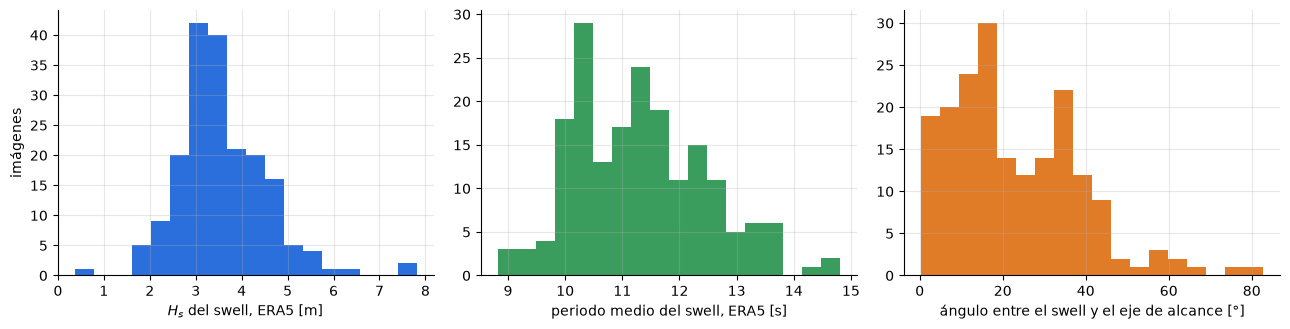

In [14]:
ED = np.load(DATOS / "sar_sitio_2016_espectros.npz")
XC, RC, GC = ED["x"].astype(np.float32), ED["rasgos"], ED["grupo"].astype(int)      # recortes: entrada CNN, rasgos CWAVE, imagen de cada recorte
IMG = pd.read_csv(DATOS / "era5_sitio_2016_imagenes.csv")
IMG["fecha"] = IMG["hora"].str[:8]; IMG["mes"] = IMG["hora"].str[4:6].astype(int)
YT = IMG[["shts", "mpts"]].values                                    # objetivos: Hs del swell [m] y periodo medio del swell [s]
DIA = IMG["fecha"].values
print(f"{len(IMG)} imágenes, {len(set(DIA))} días distintos, {len(XC)} recortes ({len(XC) / len(IMG):.1f} por imagen)")
resumen_mes = IMG.groupby("mes").agg(imágenes=("nombre", "size"), días=("fecha", "nunique"), Hs_swell_medio=("shts", "mean"), T_swell_medio=("mpts", "mean")).round(2)
display(resumen_mes.T)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
axs[0].hist(IMG["shts"], bins=18, color="#2a6fdb"); axs[0].set(xlabel="$H_s$ del swell, ERA5 [m]", ylabel="imágenes")
axs[1].hist(IMG["mpts"], bins=18, color="#3a9d5d"); axs[1].set(xlabel="periodo medio del swell, ERA5 [s]")
axs[2].hist(np.abs(((IMG["mdts"] % 180) - IMG["eje_alcance"] + 90) % 180 - 90), bins=18, color="#e07b28"); axs[2].set(xlabel="ángulo entre el swell y el eje de alcance [°]")
plt.tight_layout(); plt.show()

**Lectura.** El swell del sitio es grande y bastante homogéneo: $H_s$ del swell con media de 3,6 m y desviación típica de 1,0 m (de 0,4 a 7,8 m), y periodo medio de 8,8 a 14,8 s (media de 11,3 s, desviación típica de 1,2 s). Hay poca variación que aprender, así que **un modelo que predice siempre la media se equivoca 1,0 m en altura y 1,2 s en periodo**: esa es la referencia que hay que batir. Altura y periodo están correlacionados (0,58): el swell largo suele ser también el más alto, y la CNN podría aprovechar esa relación para adivinar una a partir de la otra. De las 187 imágenes, 173 son de la subfranja `wv1` y solo 14 de `wv2`. Y el ángulo entre el swell y el eje de alcance cubre todo el rango, lo que permite, por fin, separar el efecto del instrumento del de la dirección real del swell.

### 6.6 El método físico frente a ERA5, con 187 imágenes

Repetimos la comparación de 6.3 con todo el año. $H_{m0}$ y $T_p$ vienen de aplicar `metodo_fisico` a la imagen entera (están guardados en el CSV).

,sesgo,sesgo_pct,RMSE,correlación
Hm0 SAR frente a Hs swell ERA5 [m],-0.45,-12.57,1.10,0.52
Hm0 SAR frente a Hs total ERA5 [m],-1.34,-30.00,1.68,0.60
Tp SAR frente a T medio swell [s],3.02,26.70,4.55,0.04
Tp SAR frente a Tp ERA5 [s],2.41,20.23,4.13,0.13


dirección: error angular medio 22.5°, mediano 20.9°
referencia sin SAR (predecir la media del conjunto), RMSE de Hs del swell: 0.98 m


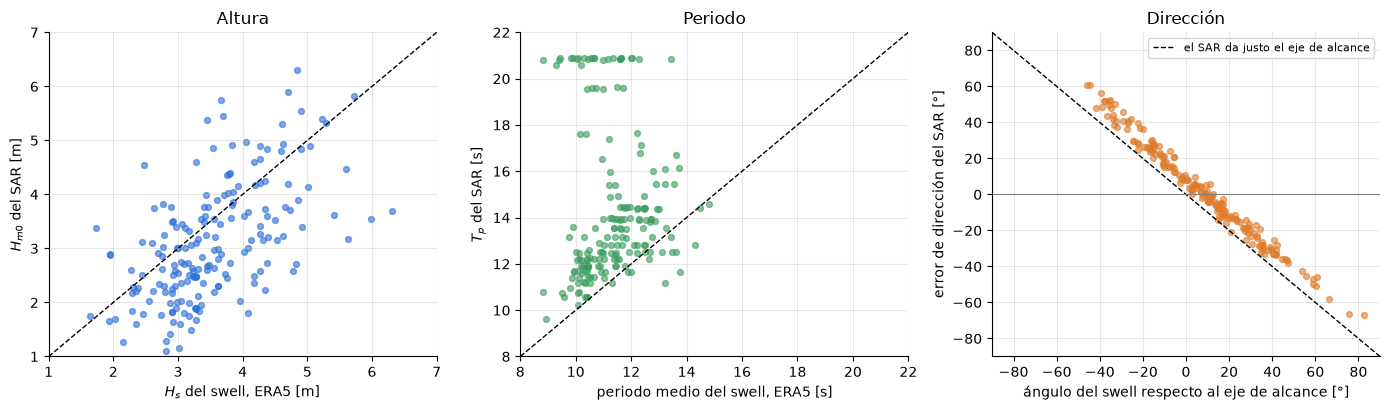

In [15]:
def resumen(p, t): return dict(sesgo=np.mean(p - t), sesgo_pct=100 * np.mean(p - t) / np.mean(t), RMSE=np.sqrt(np.mean((p - t) ** 2)), correlación=np.corrcoef(p, t)[0, 1])
tab_fis = pd.DataFrame({
    "Hm0 SAR frente a Hs swell ERA5 [m]": resumen(IMG["Hm0_sar"], IMG["shts"]),
    "Hm0 SAR frente a Hs total ERA5 [m]": resumen(IMG["Hm0_sar"], IMG["swh"]),
    "Tp SAR frente a T medio swell [s]": resumen(IMG["Tp_sar"], IMG["mpts"]),
    "Tp SAR frente a Tp ERA5 [s]": resumen(IMG["Tp_sar"], IMG["pp1d"])}).T
display(tab_fis.round(2))
d180 = lambda a, b: (a - b + 90) % 180 - 90
ang = d180(IMG["mdts"] % 180, IMG["eje_alcance"]); err_d = d180(IMG["dir_sar"], IMG["mdts"] % 180)
print(f"dirección: error angular medio {np.mean(np.abs(err_d)):.1f}°, mediano {np.median(np.abs(err_d)):.1f}°")
print("referencia sin SAR (predecir la media del conjunto), RMSE de Hs del swell:", round(float(IMG['shts'].std()), 2), "m")

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
axs[0].scatter(IMG["shts"], IMG["Hm0_sar"], s=18, alpha=0.6, color="#2a6fdb"); l = [1, 7]; axs[0].plot(l, l, "k--", lw=1)
axs[0].set(xlabel="$H_s$ del swell, ERA5 [m]", ylabel="$H_{m0}$ del SAR [m]", title="Altura", xlim=l, ylim=l)
axs[1].scatter(IMG["mpts"], IMG["Tp_sar"], s=18, alpha=0.6, color="#3a9d5d"); l = [8, 22]; axs[1].plot(l, l, "k--", lw=1)
axs[1].set(xlabel="periodo medio del swell, ERA5 [s]", ylabel="$T_p$ del SAR [s]", title="Periodo", xlim=l, ylim=l)
axs[2].scatter(ang, err_d, s=18, alpha=0.6, color="#e07b28"); x_ = np.array([-90, 90]); axs[2].plot(x_, -x_, "k--", lw=1, label="el SAR da justo el eje de alcance")
axs[2].axhline(0, color="grey", lw=0.8); axs[2].set(xlabel="ángulo del swell respecto al eje de alcance [°]", ylabel="error de dirección del SAR [°]", xlim=(-90, 90), ylim=(-90, 90), title="Dirección"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** Con 187 imágenes, el piloto de enero se confirma y se precisa.

* **Altura.** Sesgo de **-0,45 m (-13 %)** respecto al swell y de **-1,34 m (-30 %)** respecto a la altura total de ERA5; la diferencia entre ambos es el mar de viento corto, invisible para el radar. La correlación con el swell es de 0,52 y el RMSE de 1,10 m, **peor que predecir siempre la media (0,98 m)**: tal cual, el método físico no mejora la climatología del sitio. El sesgo es constante (la nube de puntos va paralela a la diagonal), así que una recta lo puede corregir (sección 6.7).
* **Periodo.** Sesgo de **+3,0 s (+27 %)** y correlación de **0,04**: sin información. Un 14 % de las imágenes sale con $T_p$ por encima de 20 s, en el extremo del intervalo de búsqueda, como se ve en el gráfico del medio. El máximo del espectro, tras dividir por $|T|^2$, cae a menudo en ruido de números de onda bajos, como sospechábamos en 6.3.
* **Dirección.** Error medio de **22,5°** (mediano 20,9°). Con todo el año el gráfico de la derecha es inequívoco: **todos los puntos están sobre la recta discontinua**. El método físico no mide la dirección del oleaje, devuelve la dirección del eje de alcance, sea cual sea el oleaje. El error es justo el ángulo entre el swell y ese eje. Una causa posible es que la inversión de este cuaderno se apoya en la modulación que domina para olas que viajan en alcance, de modo que el máximo del espectro corregido queda atrapado en ese eje (no se ha comprobado aquí). Lo que sí se ve es que el defecto es sistemático: con más datos del mismo método no desaparece.

### 6.7 Modelos entrenados con ERA5 frente a la media y el método físico calibrado

Se entrenan y se evalúan, con la misma validación cruzada agrupada por día, estos modelos para predecir la altura y el periodo del swell:

| Modelo | Entrada | Para qué sirve |
|---|---|---|
| **Media** | nada | la referencia a batir: ignora la imagen |
| **Solo metadatos** | latitud, longitud y subfranja (`wv1` o `wv2`) | **control**: ¿se puede acertar solo sabiendo dónde está la imagen, sin mirar el mar? Si sí, un buen resultado de la CNN podría ser climatología y no oleaje |
| **Método físico crudo** | la imagen | lo que hay (sección 6.6) |
| **Método físico calibrado** | la imagen | el mismo método con una recta ajustada a ERA5 (en cada fold, solo con los días de entrenamiento) |
| **XGBoost** | 30 rasgos CWAVE de cada recorte | el modelo clásico de aprendizaje automático |
| **CNN** | el espectro 2D de cada recorte (48 × 48) | la red convolucional de este cuaderno, 3 semillas por fold |

Cada recorte (6 por imagen) se predice por separado y la predicción de la imagen es la media de sus recortes. El entrenamiento de la CNN tarda unos minutos.

In [16]:
import os
from sklearn.model_selection import GroupKFold
t_cv = time.time(); torch.set_num_threads(min(4, os.cpu_count() or 1))
FOLDS = list(GroupKFold(5).split(np.arange(len(IMG)), groups=DIA))
SUB_C = np.array([float(IMG["sub"].iloc[g] == "wv2") for g in GC], np.float32)        # subfranja de cada recorte
YC = YT[GC]                                                                              # objetivo de cada recorte
PRED = {}

def a_imagen(pc, te, mte):                                           # media de los recortes de cada imagen de test
    out = np.zeros((len(IMG), pc.shape[1]))
    for g in te: out[g] = pc[GC[mte] == g].mean(0)
    return out

# 1. media y 2. solo metadatos
p_med, p_meta = np.zeros_like(YT), np.zeros_like(YT)
META = np.c_[IMG["lat"], IMG["lon"], (IMG["sub"] == "wv2").astype(float)]
for tr, te in FOLDS:
    p_med[te] = YT[tr].mean(0)
    for k in range(2):
        m = xgb.XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8, n_jobs=4).fit(META[tr], YT[tr, k]); p_meta[te, k] = m.predict(META[te])
PRED["media"], PRED["solo metadatos"] = p_med, p_meta

# 3. físico crudo y 4. calibrado
F = IMG[["Hm0_sar", "Tp_sar"]].values; p_cal = np.zeros_like(YT)
for tr, te in FOLDS:
    for k in range(2):
        a_, b_ = np.polyfit(F[tr, k], YT[tr, k], 1); p_cal[te, k] = a_ * F[te, k] + b_
PRED["físico crudo"], PRED["físico calibrado"] = F.copy(), p_cal

# 5. XGBoost sobre rasgos CWAVE
p_x = np.zeros_like(YT)
for tr, te in FOLDS:
    mtr, mte = np.isin(GC, tr), np.isin(GC, te); pc = np.zeros((mte.sum(), 2))
    for k in range(2):
        m = xgb.XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_jobs=4).fit(RC[mtr], YC[mtr, k]); pc[:, k] = m.predict(RC[mte])
    p_x += a_imagen(pc, te, mte)
PRED["XGBoost (rasgos CWAVE)"] = p_x

# 6. CNN
class CNNSitio(nn.Module):
    def __init__(s):
        super().__init__()
        s.c = nn.Sequential(nn.Conv2d(2, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(2), nn.Flatten())
        s.h = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 2))
    def forward(s, x): return s.h(s.c(x))
    def embedding(s, x): return s.c(x)

def tensores_s(X, S, mu, sd):
    x = torch.from_numpy(((X - mu) / sd)[:, None]).float()
    return torch.cat([x, torch.from_numpy(S)[:, None, None, None].expand(-1, 1, MEDIO, MEDIO)], 1)

def entrena_sitio(X, S, Y, semilla, epocas=60):
    torch.manual_seed(semilla); mu, sd = X.mean(), X.std(); ym, ys = Y.mean(0), Y.std(0)
    m = CNNSitio(); opt = torch.optim.Adam(m.parameters(), 1e-3, weight_decay=1e-3)
    xt, yt = tensores_s(X, S, mu, sd), torch.from_numpy(((Y - ym) / ys).astype(np.float32))
    for ep in range(epocas):
        m.train(); perm = torch.randperm(len(xt))
        for b in range(0, len(perm), 16):
            i = perm[b:b + 16]; opt.zero_grad(); nn.functional.mse_loss(m(xt[i]), yt[i]).backward(); opt.step()
    m.eval(); return m, (mu, sd, ym, ys)

p_c = np.zeros_like(YT)
for tr, te in FOLDS:
    mtr, mte = np.isin(GC, tr), np.isin(GC, te); pcs = []
    for sem in range(3):
        m, (mu, sd, ym, ys) = entrena_sitio(XC[mtr], SUB_C[mtr], YC[mtr], sem)
        with torch.no_grad(): pcs.append(m(tensores_s(XC[mte], SUB_C[mte], mu, sd)).numpy() * ys + ym)
    p_c += a_imagen(np.mean(pcs, 0), te, mte)
PRED["CNN"] = p_c
print(f"validación cruzada completa en {time.time() - t_cv:.0f} s")

validación cruzada completa en 148 s


Hs del swell [m]


,sesgo,RMSE,correlación
modelo,,,
media,0.00,0.99,-0.17
solo metadatos,0.01,1.10,0.04
físico crudo,-0.45,1.10,0.52
físico calibrado,-0.00,0.84,0.51
XGBoost (rasgos CWAVE),0.00,0.67,0.73
CNN,-0.01,0.61,0.79


periodo medio del swell [s]


,sesgo,RMSE,correlación
modelo,,,
media,-0.00,1.17,-0.25
solo metadatos,0.01,1.29,-0.01
físico crudo,3.02,4.55,0.04
físico calibrado,0.00,1.19,-0.27
XGBoost (rasgos CWAVE),-0.02,0.55,0.88
CNN,-0.03,0.66,0.82


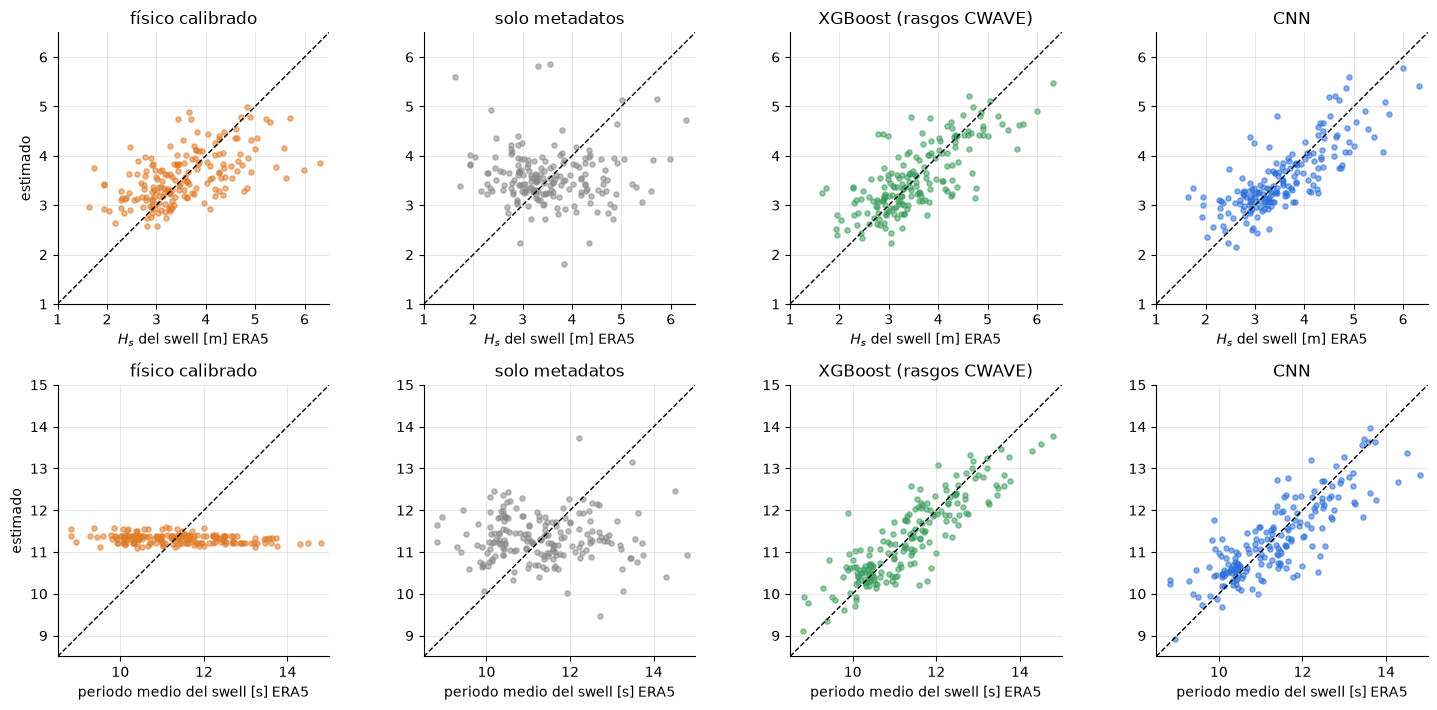

In [17]:
filas = []
for k, nombre in enumerate(["Hs del swell [m]", "periodo medio del swell [s]"]):
    for modelo, p in PRED.items():
        r = resumen(p[:, k], YT[:, k]); filas.append({"magnitud": nombre, "modelo": modelo, "sesgo": r["sesgo"], "RMSE": r["RMSE"], "correlación": r["correlación"]})
TAB = pd.DataFrame(filas)
for nombre, g in TAB.groupby("magnitud", sort=False):
    print(nombre); display(g.set_index("modelo")[["sesgo", "RMSE", "correlación"]].round(2))

fig, axs = plt.subplots(2, 4, figsize=(15, 7.2))
for k, (lab, lim) in enumerate([("$H_s$ del swell [m]", [1, 6.5]), ("periodo medio del swell [s]", [8.5, 15])]):
    for c, modelo in enumerate(["físico calibrado", "solo metadatos", "XGBoost (rasgos CWAVE)", "CNN"]):
        ax = axs[k, c]; ax.scatter(YT[:, k], PRED[modelo][:, k], s=14, alpha=0.55, color=["#e07b28", "#888", "#3a9d5d", "#2a6fdb"][c]); ax.plot(lim, lim, "k--", lw=1)
        ax.set(xlim=lim, ylim=lim, xlabel=f"{lab} ERA5", ylabel="estimado" if c == 0 else "", title=modelo, aspect="equal")
plt.tight_layout(); plt.show()

**Lectura.** Resultados fuera de entrenamiento, validación cruzada agrupada por día (86 días).

| Modelo | RMSE de $H_s$ | correlación | RMSE de $T$ | correlación |
|---|---|---|---|---|
| Media | 0,99 m | -0,17 | 1,17 s | -0,25 |
| Solo metadatos (control) | 1,10 m | 0,04 | 1,29 s | -0,01 |
| Físico calibrado | 0,84 m | 0,51 | 1,19 s | -0,27 |
| XGBoost sobre rasgos CWAVE | 0,67 m | 0,73 | **0,55 s** | **0,88** |
| CNN | **0,61 m** | **0,79** | 0,66 s | 0,82 |

* **El control pasa.** Saber solo dónde está la imagen no predice nada (RMSE peor que la media y correlación casi nula). El acierto de los otros modelos no es climatología: sale del espectro de la imagen. (La media tiene correlación negativa por una razón técnica: es la media de los días de entrenamiento y, al dejar fuera un día, se aleja un poco del valor dejado fuera.)
* **Calibrar el método físico ayuda poco.** En altura baja el RMSE de 1,10 a 0,84 m (un 15 % mejor que la media), pero en periodo no mejora la media: la recta no puede arreglar una estimación sin información. Se ve en el gráfico: el periodo calibrado es una línea horizontal.
* **Aprender del espectro gana claramente.** XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo. No usan solo el máximo del espectro: ven la forma completa (reparto de energía por número de onda y por dirección).
* **CNN frente a XGBoost: empate técnico.** La CNN es algo mejor en altura (0,61 frente a 0,67 m) y XGBoost en periodo (0,55 frente a 0,66 s). Con 86 días independientes esas diferencias no son concluyentes. XGBoost cuesta segundos; la CNN, cientos de segundos de CPU (3 semillas × 5 grupos). Para este problema y este tamaño de datos, XGBoost es la opción razonable, y la CNN solo se justificaría si se le diera más información de la que caben en 30 rasgos.
* **Las dos se encogen hacia la media en los extremos.** En los gráficos, las alturas por encima de 5 m se predicen por debajo, un efecto típico cuando hay pocos casos extremos.

### 6.8 Qué ha aprendido la CNN

Un buen número no dice **por qué** acierta. Lo comprobamos de dos maneras con una CNN entrenada con todos los recortes.

1. **Sonda lineal sobre la capa intermedia.** Los 64 valores que la CNN calcula antes de la cabeza de regresión (su representación interna) se usan para predecir con una regresión lineal regularizada (Ridge) distintas propiedades, con validación agrupada por día. Medimos el $R^2$ (coeficiente de determinación: 1 es acierto perfecto, 0 es lo que da la media, negativo es peor que la media). Si la red "sabe" una propiedad, la sonda la recupera. Se incluyen controles: las mismas propiedades a partir de 64 componentes principales (PCA, análisis de componentes principales) de los píxeles de entrada, y una propiedad **aleatoria** que no puede predecirse.
2. **Dónde mira.** El gradiente de la salida respecto a cada celda del espectro de entrada dice qué números de onda cambian la predicción. Se promedia en anillos de número de onda $k$ (el número de ondas por unidad de longitud, $k = 2\pi/\lambda$, con $\lambda$ la longitud de onda) y se compara con la banda en la que ERA5 dice que está el swell, usando la relación de las olas profundas $k = (2\pi/T)^2 / g$ (con $g = 9{,}81\ \mathrm{m/s^2}$ la gravedad y $T$ el periodo).

,representación de la CNN,píxeles (PCA 64)
Hs del swell,0.66,-0.05
periodo del swell,0.69,0.59
ángulo swell-eje de alcance,0.25,-0.18
subfranja (wv1/wv2),0.96,0.73
desviación típica de la imagen,0.77,0.75
propiedad aleatoria (control),-0.09,-0.89


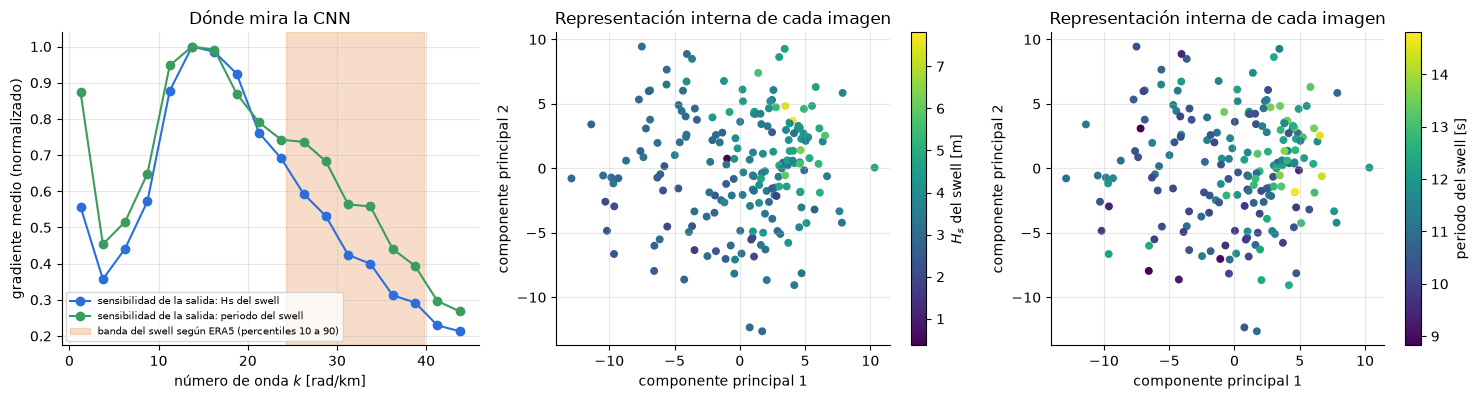

sección 6.8 en 13 s


In [18]:
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
t_8 = time.time()
mod_f, (mu_f, sd_f, ym_f, ys_f) = entrena_sitio(XC, SUB_C, YC, 0)
with torch.no_grad():
    EMB = mod_f.embedding(tensores_s(XC, SUB_C, mu_f, sd_f)).numpy()
EMB_IMG = np.array([EMB[GC == g].mean(0) for g in range(len(IMG))])                          # representación media por imagen
PIX_IMG = np.array([XC[GC == g].reshape((GC == g).sum(), -1).mean(0) for g in range(len(IMG))])
PIX64 = PCA(64, random_state=0).fit_transform(PIX_IMG)
ang_sw = np.abs(d180(IMG["mdts"] % 180, IMG["eje_alcance"]))
rng = np.random.default_rng(0)
PROP = {"Hs del swell": IMG["shts"].values, "periodo del swell": IMG["mpts"].values, "ángulo swell-eje de alcance": ang_sw.values if hasattr(ang_sw, "values") else ang_sw,
        "subfranja (wv1/wv2)": (IMG["sub"] == "wv2").astype(float).values, "desviación típica de la imagen": IMG["rms_img"].values, "propiedad aleatoria (control)": rng.normal(size=len(IMG))}
def r2_cv(Xf, y):
    p = np.zeros(len(y))
    for tr, te in FOLDS:
        mu, sd = Xf[tr].mean(0), Xf[tr].std(0) + 1e-9
        p[te] = Ridge(alpha=10).fit((Xf[tr] - mu) / sd, y[tr]).predict((Xf[te] - mu) / sd)
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
SONDA = pd.DataFrame({n: {"representación de la CNN": r2_cv(EMB_IMG, y), "píxeles (PCA 64)": r2_cv(PIX64, y)} for n, y in PROP.items()}).T
display(SONDA.round(2))

# Dónde mira: gradiente medio de cada salida respecto al espectro de entrada
x_t = tensores_s(XC, SUB_C, mu_f, sd_f).requires_grad_(True); sal = []
for k in range(2):
    g_acum = np.zeros((MEDIO, MEDIO))
    for i in range(0, len(x_t), 128):
        xb = x_t[i:i + 128].detach().clone().requires_grad_(True); mod_f(xb)[:, k].sum().backward(); g_acum += np.abs(xb.grad[:, 0].numpy()).sum(0)
    sal.append(g_acum / len(x_t))

# Número de onda de cada celda de la entrada (48 x 48): ventana de Welch de 128 px, píxel de unos 40 m, celdas promediadas de 2 en 2
DK = 2 * np.pi / (VEN * 40.0)
cen = (-47.5 + 2 * np.arange(MEDIO)) * DK
KK = np.hypot(*np.meshgrid(cen, cen))
bordes = np.linspace(0, 0.045, 19); cb = 0.5 * (bordes[1:] + bordes[:-1])
perf = [np.array([s_[(KK >= a) & (KK < b)].mean() for a, b in zip(bordes[:-1], bordes[1:])]) for s_ in sal]
perf = [p / p.max() for p in perf]
k_sw = (2 * np.pi / np.percentile(IMG["mpts"], [10, 90])) ** 2 / G

fig, axs = plt.subplots(1, 3, figsize=(15, 4.1))
for k, (nombre, col) in enumerate([("Hs del swell", "#2a6fdb"), ("periodo del swell", "#3a9d5d")]):
    axs[0].plot(cb * 1e3, perf[k], "o-", color=col, label=f"sensibilidad de la salida: {nombre}")
axs[0].axvspan(k_sw[1] * 1e3, k_sw[0] * 1e3, color="#e07b28", alpha=0.25, label="banda del swell según ERA5 (percentiles 10 a 90)")
axs[0].set(xlabel="número de onda $k$ [rad/km]", ylabel="gradiente medio (normalizado)", title="Dónde mira la CNN"); axs[0].legend(fontsize=7)
pc2 = PCA(2, random_state=0).fit_transform((EMB_IMG - EMB_IMG.mean(0)) / (EMB_IMG.std(0) + 1e-9))
for ax, (v, nombre) in zip(axs[1:], [(IMG["shts"], "$H_s$ del swell [m]"), (IMG["mpts"], "periodo del swell [s]")]):
    sc = ax.scatter(pc2[:, 0], pc2[:, 1], c=v, s=22, cmap="viridis"); plt.colorbar(sc, ax=ax, label=nombre)
    ax.set(xlabel="componente principal 1", ylabel="componente principal 2", title="Representación interna de cada imagen")
plt.tight_layout(); plt.show()
print(f"sección 6.8 en {time.time() - t_8:.0f} s")

**Lectura.**

* **La representación interna contiene la altura y el periodo.** Con la representación de la CNN, una regresión lineal recupera la altura con $R^2$ = 0,66 y el periodo con 0,69. Con 64 componentes principales de los píxeles de entrada, solo -0,05 y 0,59: la red ha reorganizado el espectro de forma que esas dos magnitudes quedan disponibles linealmente, sobre todo la altura. (La comparación es algo injusta para los píxeles: con 64 dimensiones y 187 imágenes la sonda sobreajusta, como delata el control aleatorio, que da -0,89 con píxeles y -0,09 con la CNN, donde el valor correcto es 0.)
* **También contiene mucho que no es oleaje.** La subfranja (`wv1` o `wv2`, que es el ángulo de incidencia del radar) se recupera con $R^2$ = 0,96 (aunque solo 14 de las 187 imágenes son `wv2`) y la desviación típica de la imagen con 0,77. Era de esperar: ese ángulo cambia la forma del espectro, y la red lo necesita para interpretarlo. La dirección relativa al eje de alcance apenas está (0,25).
* **Dónde mira.** El gradiente es mayor entre unos 10 y 20 rad/km (longitudes de onda de 300 a 600 m) para las dos salidas, y menor en la banda donde ERA5 sitúa el swell (de 24 a 40 rad/km, es decir, de 160 a 260 m), donde cae de un 70 a 75 % del máximo a un 30 a 40 %. O sea, la red no se fija sobre todo en el pico del swell, sino en la cola de longitudes de onda largas del espectro. Es una pista, no una prueba: un gradiente grande dice que esa zona cambia la salida, no que sea la causa física.
* **Un solo eje domina.** En la proyección en dos componentes principales, tanto la altura como el periodo aumentan hacia la derecha: la red ha aprendido sobre todo un eje de "swell largo y alto". Como altura y periodo están correlacionados en este sitio (0,58), parte del acierto de una puede venir de la otra.

### 6.9 Serie temporal del año: ERA5 frente a las estimaciones SAR

Por último, la serie de un solo sitio a lo largo de 2016. La línea gris es ERA5 cada hora en el centro del sitio (55°S 90°W). Los puntos son las imágenes, a la hora a la que pasó el satélite, con la estimación de cada modelo **fuera de entrenamiento** (la de la validación cruzada de 6.7: ninguna imagen se predice con un modelo que haya visto su día). Los huecos son abril y agosto, que no se descargaron.

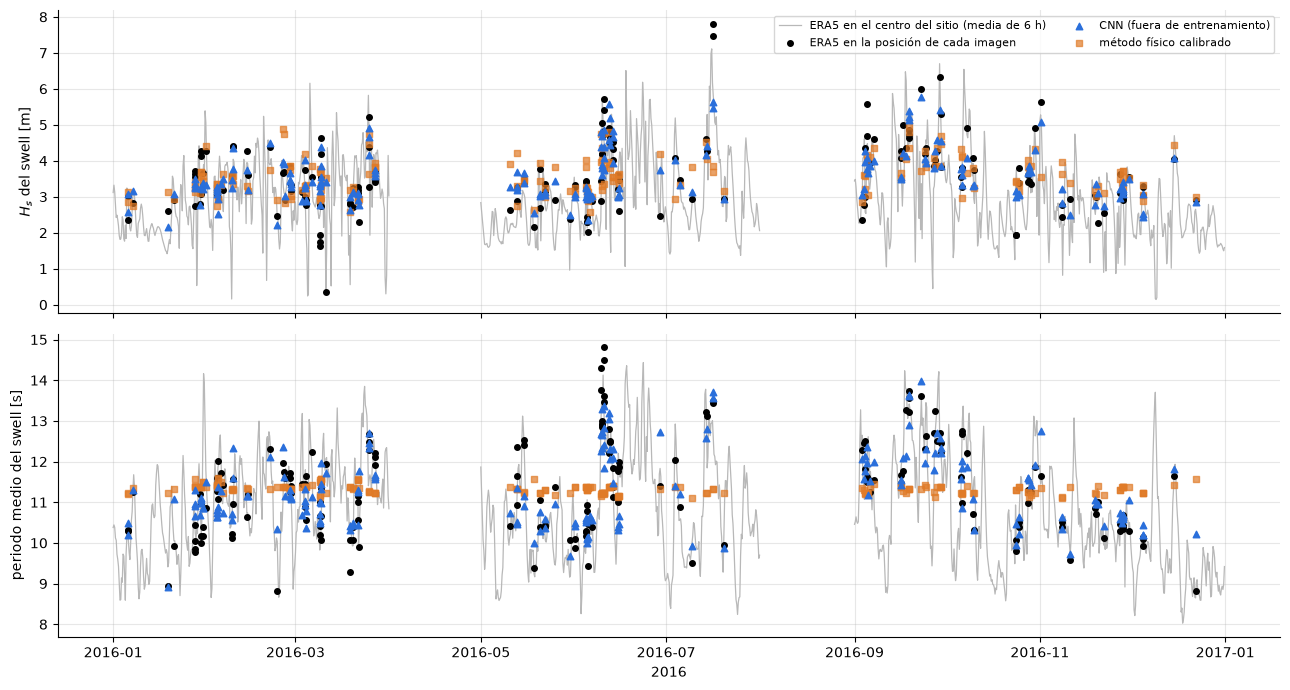

mes,1,2,3,5,6,7,9,10,11,12
imágenes,16.00,24.00,30.00,13.00,34.00,8.00,25.00,16.00,16.00,5.00
ERA5_Hs,3.31,3.51,3.08,3.02,3.73,4.70,4.37,3.56,3.13,3.32
CNN_Hs,3.12,3.40,3.41,3.17,3.75,4.14,4.21,3.54,3.21,2.99
físico_calibrado_Hs,3.33,3.44,3.42,3.41,3.62,3.67,3.98,3.71,3.46,3.34
ERA5_T,10.29,11.27,11.12,11.03,11.83,11.95,12.39,11.17,10.51,10.12
CNN_T,10.80,11.16,11.17,10.60,11.53,11.88,12.24,11.18,10.77,10.57


correlación de la media mensual de Hs, CNN frente a ERA5: 0.91 (con solo 10 meses)


In [19]:
SER = pd.read_csv(DATOS / "era5_serie_sitio_2016.csv")
SER["t"] = pd.to_datetime(SER["hora"], format="%Y%m%dt%H%M%S"); IMG["t"] = pd.to_datetime(IMG["hora"], format="%Y%m%dt%H%M%S")
fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for k, (col, lab) in enumerate([("shts", "$H_s$ del swell [m]"), ("mpts", "periodo medio del swell [s]")]):
    ax = axs[k]; ss = SER.set_index("t")[col].resample("6h").mean()
    ax.plot(ss.index, ss.values, color="#b8b8b8", lw=0.9, label="ERA5 en el centro del sitio (media de 6 h)")
    ax.scatter(IMG["t"], IMG[col], s=16, color="k", zorder=3, label="ERA5 en la posición de cada imagen")
    ax.scatter(IMG["t"], PRED["CNN"][:, k], s=22, marker="^", color="#2a6fdb", zorder=4, label="CNN (fuera de entrenamiento)")
    ax.scatter(IMG["t"], PRED["físico calibrado"][:, k], s=18, marker="s", color="#e07b28", alpha=0.7, zorder=3, label="método físico calibrado")
    ax.set(ylabel=lab)
axs[0].legend(fontsize=8, ncol=2, loc="upper right"); axs[1].set_xlabel("2016"); plt.tight_layout(); plt.show()

mens = IMG.assign(CNN_Hs=PRED["CNN"][:, 0], fis_Hs=PRED["físico calibrado"][:, 0], CNN_T=PRED["CNN"][:, 1]).groupby("mes").agg(
    imágenes=("nombre", "size"), ERA5_Hs=("shts", "mean"), CNN_Hs=("CNN_Hs", "mean"), físico_calibrado_Hs=("fis_Hs", "mean"), ERA5_T=("mpts", "mean"), CNN_T=("CNN_T", "mean")).round(2)
display(mens.T)
r_mens = np.corrcoef(mens["ERA5_Hs"], mens["CNN_Hs"])[0, 1]
print(f"correlación de la media mensual de Hs, CNN frente a ERA5: {r_mens:.2f} (con solo {len(mens)} meses)")

**Lectura.**

* **La CNN sigue la estructura de la serie, no cada detalle.** En los dos paneles, los triángulos azules suben y bajan con los puntos negros: los temporales de junio y julio (altura de 4 a 5 m, periodo de 12 a 14 s) y de septiembre se reconocen, y las calmas de enero y marzo también. El método físico calibrado (cuadrados naranjas) es casi una línea plana en la media, sobre todo en periodo.
* **A escala mensual la señal es clara.** La correlación entre la media mensual de la CNN y la de ERA5 es de 0,91, con la limitación obvia de que son solo 10 meses. La CNN reproduce el ciclo estacional (altura máxima en julio y septiembre) pero lo atenúa: 4,14 m frente a 4,70 m en julio.
* **Los extremos se subestiman.** El punto más alto de ERA5 (unos 7,8 m en julio) queda en unos 4 a 5 m en la CNN. Con pocos casos extremos en el entrenamiento, una red de regresión tiende a la media. Para una aplicación operativa (por ejemplo, alertas de temporal) esto es un límite serio.

### 6.10 Límites de lo medido y qué falta

* **Un solo sitio y un solo año.** Todo vale para el Pacífico sur frente a Chile en 2016, con swell grande y poco mar de viento. Otros regímenes (mares cortos, mar cruzado, trópico) no están medidos.
* **86 días independientes.** La validación agrupada por día es lo correcto, pero con tan pocos grupos las diferencias pequeñas entre modelos (por ejemplo CNN frente a XGBoost) no son concluyentes. Un intervalo de confianza por *bootstrap* sobre los días lo cuantificaría.
* **ERA5 no es la verdad.** Es un reanálisis: un modelo de olas que asimila medidas. Puede compartir errores con lo que la CNN aprende. Una referencia independiente (boyas, altímetros) cerraría la pregunta, pero cerca de 55°S 90°W no hay boyas.
* **Las etiquetas son del swell, no de todo el mar.** El SAR en modo oleaje no ve el mar de viento corto (menos de 100 m). Por eso se compara con el swell y no con la altura total.
* **Lo que no se hizo:** preentrenar la CNN con las escenas simuladas de la sección 2 y ajustarla con estas imágenes; estimar la dirección con la CNN (el método físico la deja pegada al eje de alcance); usar la imagen completa en vez de recortes; una segunda región.


### 6.11 Apéndice: cómo repetir la descarga (CDS y SEANOE)

Para saber si alguno de estos métodos acierta con el mar real hace falta una referencia independiente. La opción gratuita y global es el reanálisis **ERA5** del ECMWF (Copernicus Climate Change Service). **Este apéndice no se ejecuta**: resume cómo se hizo la descarga y deja el código para repetirla.

#### Cuenta y datos

1. Crear una cuenta gratuita en el **Climate Data Store (CDS)**: <https://cds.climate.copernicus.eu>.
2. En la página del conjunto *ERA5 hourly data on single levels* ([enlace](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)) aceptar las condiciones de uso (sin ese paso la API rechaza la petición).
3. Copiar la clave personal desde el perfil del CDS a `~/.cdsapirc`:
   ```
   url: https://cds.climate.copernicus.eu/api
   key: <TU-CLAVE-PERSONAL>
   ```
   e instalar el cliente: `pip install "cdsapi>=0.7.2"`.
4. Variables de oleaje de ERA5 que hay que pedir:

| Variable de la API | Qué es | Se compara con |
|---|---|---|
| `significant_height_of_combined_wind_waves_and_swell` | $H_s$ total | $H_{m0}$ de la viñeta (solo si el mar de viento es pequeño) |
| `peak_wave_period` | periodo de pico del espectro total | $T_p$ |
| `mean_wave_direction` | dirección **desde** la que viene el oleaje | dirección (módulo 180°) |
| `significant_height_of_total_swell` | $H_s$ del swell | $H_{m0}$ (comparación más justa: el SAR ve solo swell) |
| `mean_period_of_total_swell` | periodo medio del swell | $T_p$ (ojo: es periodo **medio**, no de pico) |
| `mean_direction_of_total_swell` | dirección media del swell | dirección |

#### Más viñetas de TenGeoP-SARwv sin bajar 31 GB

Los dos ficheros `.tar.gz` de SEANOE (15 y 16 GB) mezclan las diez clases. Como un `.tar.gz` se lee en orden, basta bajar el **principio** con una petición HTTP por rango: unos 300 MB dan unas 85 imágenes de la clase F. El final truncado hace que `tar` termine con un error que se puede ignorar.

```bash
# etiquetas (nombre, clase, subfranja, hora, lon, lat) y definiciones de las clases
curl -sL -o etiquetas.txt https://www.seanoe.org/data/00456/56796/data/58683.txt
# primeros 300 MB del primer fichero de imágenes
curl -sL -r 0-300000000 -o parte1.tgz https://www.seanoe.org/data/00456/56796/data/58684.tar.gz
# extraer solo la clase F ("Pure Ocean Waves"); el error final de tar por el gzip truncado es esperado
mkdir -p viñetas && tar xzf parte1.tgz -C viñetas --wildcards 'GeoTIFF/F/*'
```

Para unas 1 000 viñetas hace falta bajar unos 3,5 GB repartidos entre los dos ficheros. Hay que repetir con el segundo fichero (`58685.tar.gz`) y comprobar que las viñetas extraídas aparecen en `etiquetas.txt`, que da la hora y la posición.

#### Colocalizar y comparar (esqueleto sin ejecutar)

```python
import cdsapi, xarray as xr, pandas as pd, numpy as np

# 1) Lista de viñetas clase F con hora y posición, a partir de etiquetas.txt
et = pd.read_csv("etiquetas.txt", sep=" ", header=None, names=["archivo", "clase", "subfranja", "hora", "lon", "lat"])
et = et[et.clase == "F"].assign(hora=lambda d: pd.to_datetime(d.hora, format="%Y%m%dt%H%M%S"))

# 2) Una petición por día para no pasar del límite de campos por solicitud
c = cdsapi.Client()
VARS = ["significant_height_of_combined_wind_waves_and_swell", "peak_wave_period", "mean_wave_direction",
        "significant_height_of_total_swell", "mean_period_of_total_swell", "mean_direction_of_total_swell"]
for dia, g in et.groupby(et.hora.dt.date):
    c.retrieve("reanalysis-era5-single-levels", {
        "product_type": "reanalysis", "variable": VARS, "year": f"{dia:%Y}", "month": f"{dia:%m}", "day": f"{dia:%d}",
        "time": [f"{h:02d}:00" for h in range(24)], "data_format": "netcdf"}, f"era5_{dia}.nc")

# 3) Colocalizar: punto de malla más cercano y hora más cercana (ERA5 de oleaje: malla de 0.5°, cada hora)
def era5_en(fila):
    ds = xr.open_dataset(f"era5_{fila.hora.date()}.nc")
    return ds.sel(latitude=fila.lat, longitude=fila.lon % 360 if ds.longitude.max() > 180 else fila.lon,
                  valid_time=fila.hora, method="nearest")

# 4) Tabla final: CNN, físico y ERA5 para cada viñeta (usando las funciones de este cuaderno)
#    columnas: Hm0_cnn, Hm0_fisico, Hm0_era5_swell, Tp_cnn, Tp_era5, dir_cnn, dir_era5, ...
```


#### Métricas y precauciones

* **Métricas por método:** sesgo, RMSE y correlación de $H_{m0}$ frente a la $H_s$ del swell de ERA5; RMSE de $T_p$; error angular medio (con ambigüedad de 180°). Si sale una dispersión grande, separar por subfranja y por dirección respecto al eje de alcance: ahí está el efecto de la saturación.
* **ERA5 no es la verdad.** Es un modelo con asimilación de altimetría: su error típico en $H_s$ es de unos 0,3 a 0,5 m, y en periodo y dirección del swell es mayor. Además la malla de oleaje es de 0,5° (unos 55 km) y la viñeta cubre 20 km. Conviene descartar viñetas con gradientes fuertes (borde de hielo, cerca de tierra) y reportar la **incertidumbre de la referencia** junto a las métricas.
* **Periodo medio frente a periodo de pico.** `mean_period_of_total_swell` no equivale a nuestro $T_p$: o se compara con el periodo medio del espectro estimado o se usa `peak_wave_period` cuando el swell domina.
* **Partición correcta.** El SAR ve el swell; comparar con $H_s$ del **total** solo tiene sentido si el mar de viento es pequeño. Si no, usar el swell de ERA5.
* **Evitar la fuga de información.** Al ajustar la CNN con estas etiquetas, partir entrenamiento y test por **día y región** (viñetas vecinas son casi la misma escena).


#### Ajuste fino de la CNN con etiquetas ERA5

1. Partir de la CNN entrenada con la **mezcla** (la que ya conoce la saturación).
2. Congelar las capas de convolución y reentrenar solo la cabeza densa con las viñetas colocalizadas (decenas o pocos cientos de ejemplos bastan para corregir sesgos de escala).
3. Si hay más de unos cientos, descongelar todo con una tasa de aprendizaje 10 veces menor.
4. Comparar, con la misma partición por día y región, **CNN ajustada** frente a **método físico** frente a **XGBoost reentrenado con los mismos rasgos**. Si la CNN ajustada no gana con claridad en el test, el resultado honesto es que no hace falta una red.

**Criterio de éxito antes de mirar.** Que $H_{m0}$ de la CNN ajustada tenga un RMSE menor que el del método físico con un intervalo de confianza (remuestreo *bootstrap* por días) que no se solape, y que el sesgo no dependa de la dirección respecto al eje de alcance.


## 7. Conclusión: cuándo usar una CNN para oleaje desde SAR

| Situación | Mejor opción con los números de este cuaderno |
|---|---|
| La física es conocida y los datos entran en el rango (test A y C) | **Inversión física**: la más barata (no se entrena), la que extrapola, y la mejor en $H_{m0}$ |
| Hay que estimar periodo y dirección con la máxima precisión dentro del rango | **XGBoost** sobre rasgos CWAVE (7 s de entrenamiento, 0,23 s y 1,0°), igual o mejor que la CNN |
| Hay un efecto no lineal que la física no cubre **y** tienes un simulador o etiquetas reales que lo contienen (test B) | **CNN o XGBoost entrenados con ese efecto**: pasan de −41 % de sesgo a unos −3 %. La CNN gana poco a XGBoost en altura |
| Entrada con estructura espacial que no se resume en rasgos (imagen cruda, bandas de varias polarizaciones, series de viñetas) | **CNN**: aquí XGBoost necesita rasgos hechos a mano. No lo hemos probado porque el espectro 2D ya es una buena entrada |
| Fuera de todo lo visto (olas más altas, otra física) | Ninguno de los modelos aprendidos: hay que **medir** |

Dos ideas para llevarse:

1. **Aprender no sustituye a validar.** Los números "buenos" de la sección 4 son consistencia con el simulador. El dato clave, el sesgo de $H_{m0}$ en el mar real, ya está medido con ERA5 (sección 6, 187 imágenes): el método físico da un 13 % menos de altura que el swell de ERA5, un periodo sin información y una dirección que es siempre el eje de alcance. La CNN con una física simulada daba la mitad y con otra el doble; con etiquetas reales, las dos cosas se corrigen.
2. **El valor de una CNN aquí no es la arquitectura, es la etiqueta.** Con etiquetas ERA5, la CNN y XGBoost bajaron el error de altura un 38 % y un 32 % respecto a predecir la media, y el de periodo un 44 % y un 53 %, mientras el método físico calibrado solo mejoró la altura un 15 %. Pero entre la CNN y XGBoost no hay una diferencia concluyente con 86 días independientes, y XGBoost cuesta segundos. La CNN justificaría su coste con más datos, otras regiones o entradas que no se resuman en 30 rasgos.
3. **Controlar antes de creer.** El modelo que solo conoce la posición de la imagen no mejora a la media: sin ese control, el buen resultado podría ser climatología. Y la sonda sobre la capa intermedia mostró que la red también codifica el modo del instrumento, lo que obliga a vigilar que no lo use como atajo.

In [20]:
print(f"Tiempo total de ejecución del notebook: {time.time() - T0:.0f} s")

Tiempo total de ejecución del notebook: 285 s



## 8. Ejercicios

1. Cambia el recorte `MEDIO` de 48 a 32 celdas: ¿cuánto empeora la estimación de $T_p$ para periodos cortos (9 a 11 s)?
2. Añade ruido de ±10 % al tamaño de píxel en el test: ¿qué método es más sensible, la CNN o la inversión física?
3. Prueba una CNN que reciba la imagen reducida en lugar del espectro. ¿Aprende por sí sola el espectro? ¿Cuántas escenas necesita?
4. Con los 86 días de la sección 6.5, calcula un intervalo de confianza por *bootstrap* (remuestreando días) para la diferencia de RMSE de altura entre la CNN y XGBoost. ¿Incluye el cero?
5. Añade a XGBoost los 64 valores de la capa intermedia de la CNN (sección 6.8) como rasgos. ¿Mejora a cada uno por separado?
6. Preentrena la CNN con las escenas simuladas de la sección 2 y ajústala con las imágenes de 2016. ¿Baja el error en las alturas por encima de 5 m, que ahora se subestiman?
7. Quita la subfranja de las entradas de la CNN. ¿Cambia el resultado? ¿Y si quitas solo las 14 imágenes `wv2`?

**Referencias**

* Wang, C., Mouche, A., Tandeo, P. et al. (2019). *A labelled ocean SAR imagery dataset of ten geophysical phenomena from Sentinel-1 wave mode*. Geoscience Data Journal, 6(2), 105-115. [Artículo (doi:10.1002/gdj3.73)](https://doi.org/10.1002/gdj3.73). Datos: [doi:10.17882/56796](https://doi.org/10.17882/56796), [SEANOE](https://www.seanoe.org/data/00456/56796/) (CC BY-NC-SA 4.0).
* Alpers, W. R., Ross, D. B. y Rufenach, C. L. (1981). *On the detectability of ocean surface waves by real and synthetic aperture radar*. Journal of Geophysical Research, 86(C7), 6481-6498. [doi:10.1029/JC086iC07p06481](https://doi.org/10.1029/JC086iC07p06481).
* Hasselmann, K. y Hasselmann, S. (1991). *On the nonlinear mapping of an ocean wave spectrum into a synthetic aperture radar image spectrum*. Journal of Geophysical Research, 96(C6), 10713-10729. [doi:10.1029/91JC00302](https://doi.org/10.1029/91JC00302).
* Quach, B., Glaser, Y., Stopa, J. E., Mouche, A. A. y Sadowski, P. (2021). *Deep learning for predicting significant wave height from synthetic aperture radar*. IEEE Transactions on Geoscience and Remote Sensing, 59(3), 1859-1867 (publicado en línea en 2020). [doi:10.1109/TGRS.2020.3003839](https://doi.org/10.1109/TGRS.2020.3003839).
* ERA5: Hersbach, H. et al. (2020). *The ERA5 global reanalysis*. Quarterly Journal of the Royal Meteorological Society, 146(730), 1999-2049. [doi:10.1002/qj.3803](https://doi.org/10.1002/qj.3803). Datos: Copernicus Climate Change Service (C3S), [ERA5 hourly data on single levels](https://doi.org/10.24381/cds.adbb2d47) ([descarga en el Climate Data Store](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)).